In [ ]:
import time
from ugot import ugot
got=ugot.UGOT()
got.initialize('192.168.1.190')
got.play_audio_tts("Hello World.")
got.show_light_rgb_effect(0, 225,0,3)
time.sleep(2)
got.turn_off_lights()

In [ ]:
# laser sensor
Laser1 = got.read_distance_data(21)
Laser2 = got.read_distance_data(51)
print(f"The Laser1 value is {Laser1}.")
print(f"The Laser2 value is {Laser2}.")

In [ ]:
# OpenCV libiary
import numpy as np
import cv2
from IPython.display import display, Image,clear_output
import matplotlib.pyplot as plt
import os

In [ ]:
# import YOLO
import ultralytics
from ultralytics import YOLO
import cv2
from IPython.display import Image, display

ultralytics.checks()
model = YOLO("yolo26n.pt")
print("Model is ready.")

In [ ]:
pip show opencv-python

In [ ]:
got.open_camera()
print("The camera is on.")
picture_raw = got.read_camera_data()
picture_1D = np.frombuffer(picture_raw,np.uint8)
picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  
ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
display(Image(picture_jpg.tobytes()))

In [ ]:
# Step 1: turn on the camera
got.open_camera()
print("The camera is on.")

# Step 2: get the raw data
picture = got.read_camera_data()
print(f"The raw data:{picture}")
print(f"Data type:{type(picture)}")

# Step 3: unpack the raw data, bytes to 1 D array
picture= np.frombuffer(picture,np.uint8)
print(f"The data:{picture}")
print(f"Shape:{picture.shape}")
print(f"Data type:{type(picture)}")

# Step 4: 1D array to 3D array
picture = cv2.imdecode(picture,cv2.IMREAD_COLOR)
print(f"The data:{picture}")
print(f"Shape:{picture.shape}")
print(f"Data type:{type(picture)}")

# Step 5: pack the 3D array for Jupyter
ok,picture_jpg= cv2.imencode(".jpg",picture)
print(f"The data:{picture}")
print(f"Shape:{picture.shape}")
print(f"Data type:{type(picture)}")

# Step 6: Show the image on screen
display(Image(picture_jpg.tobytes()))

# Level 4 Term 1

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image

## Session 3

In [ ]:
for i in range(5):
    got.mecanum_move_speed_times(0,25,50,1)
    got.mecanum_turn_speed_times(2,30,72,2)
print("Mission completed")

In [ ]:
import time
got.load_models(["apriltag_qrcode"])
AP_info = got.get_apriltag_total_info()

for i in range(10):
    AP_info = got.get_apriltag_total_info()
    print(AP_info)
    time.sleep(0.5)

In [ ]:
# check point game
import time
got.load_models(["apriltag_qrcode"])
AP_info = got.get_apriltag_total_info()

check_point =("AP_5",2,90,60) # name,direction, degrees, distance

while True:
    AP_info = got.get_apriltag_total_info()
    if not AP_info:
        print("Show me the apriltag please.")
        time.sleep(0.5)
        continue

    tag_name = f"AP_{AP_info[0][0]}"

    if tag_name == check_point[0]:
        print(f"I found {tag_name}")
        direction = check_point[1]
        degrees = check_point[2]
        distance = check_point[3]
        got.mecanum_turn_speed_times(direction,30,degrees,2)
        got.mecanum_move_speed_times(0,25,distance,1)
        print("Mission completed")
        break


## Session 4

In [ ]:
my_friend = (1000,True,"banana",("blue,yellow,green"),["dog","cat"])
age,*others,pet = my_friend
print(f"My friend is {age} years old,and he has a {pet[0]} at home.")

In [ ]:
import time
got.load_models(["apriltag_qrcode"])
check_points = (("AP_6", 2, 45, 60),
                ("AP_2", 3, 105, 80))

for name, direction, degrees, distance in check_points:
    print(f"I am looking for {name}")
    got.mecanum_turn_speed(2, 20)

    while True:
        AP_info = got.get_apriltag_total_info()

        if not AP_info:
            print("Show me the apriltag!")
            time.sleep(0.2)
            continue

        tag_name = f"AP_{AP_info[0][0]}"

        if tag_name != name:
            time.sleep(0.05)
            continue

        got.mecanum_stop()
        print(f"I found the correct Apriltag: {tag_name}")

        got.mecanum_turn_speed_times(direction, 30, degrees, 2) 
        got.mecanum_move_speed_times(0, 25, distance, 1)         

        break

    print("Mission completed.")


## Session 5

In [ ]:
my_friend1 = ["Jack",1000,"Mars","Apple",["blue","yellow"]]
my_friend2 = ("Jack",1000,"Mars","Apple",("blue","yellow"))
print(my_friend1)
print(my_friend2)
print(my_friend1[4][0])
print(my_friend2[4][1])

1. create a dictionary

In [ ]:
my_friend3= {
    "name":"Jack",    # in dictionary we have to use key:value pair for the item.
    "age":1000,
    "birth planet":"Mars",
    "fruit":"apple",
    "color":"blue,yellow",
}
print(my_friend3)
print(type(my_friend1))
print(type(my_friend2))
print(type(my_friend3))

2. access items

In [ ]:
print(my_friend3["name"])
print(my_friend3.keys())
print(my_friend3.values())
print(my_friend3.items())

3. change items

In [ ]:
my_friend3["name"] = "John"   # change value
my_friend3["age"] = 500
my_friend3["sports"] = "football,basketball"  # add item
my_friend3.pop("fruit")   # we use .pop statement to delet an item
print(my_friend3)

4. the dictionary and laser sensor

In [ ]:
import time
Laser1 = got.read_distance_data(21)

distance = {
    "go":{"range":100,"color":"green"},
    "slow":{"range":30,"color":"blue"},
    "stop":{"range":0,"color":"red"},
}

while True:
    Laser1 = got.read_distance_data(21)
    print(f"The laser sensor value is {Laser1}")

    if Laser1>distance["go"]["range"]:
        action = "go"
    elif Laser1>distance["slow"]["range"]:
        action = "slow"
    else:
        action = "stop"
    color = distance[action]["color"]

    if color=="red":
        got.show_light_rgb_effect(255,0,0,3)
    elif color == "green":
        got.show_light_rgb_effect(0,255,0,3)
    else:
        color=="blue"
        got.show_light_rgb_effect(0,0,255,3)

    if action == "stop":
        break
    time.sleep(0.5)



## Session 7

In [ ]:
my_friend6 = {
    "name":"Jack",
    "age":1000,
    "birth planet":"Mars",
    "fruit":["apple","banana","orange"],}
print(my_friend6)

In [ ]:
print(my_friend6.keys())
print(my_friend6.values())

In [ ]:
my_friend6["age"] = 11
print(my_friend6)

In [ ]:
my_friend6["color"] = "red"
print(my_friend6)

1. loop dictionary

In [ ]:
for i in my_friend6:
    print(i)
for i in my_friend6.values():
    print(i)
for i in my_friend6.items():
    print(i)

In [ ]:
for i,j in my_friend6.items():
    print(i,j)

2. nested dictionaries

In [ ]:
classmate1= {
    "name":"Alice",
    "age":10,}
classmate2= {
    "name":"Bob",
    "age":11,}
classmate3= {
    "name":"Cathy",
    "age":9,}
classmates = {
    "classmate1":classmate1,
    "classmate2":classmate2,
    "classmate3":classmate3,}

print(classmates)
for i,j in classmates.items():
    print(i,j)

print(classmates["classmate1"]["name"])

3. voice recognition and chassis control

In [ ]:
import time
asr_result = got.start_audio_asr()
got.start_audio_nlp(asr_result,True)
print(asr_result)

In [ ]:
got.mecanum_move_xyz(0,0,0)

In [ ]:
COMMANDS = {
    "forward":(0,10,0),
    "backward":(0,-10,0),
    "left":(-10,0,0),
    "right":(10,0,0),
    "rotate":(0,0,10),
}

print("Plese give me a command")

while True:
    asr_result = got.start_audio_asr()
    if not asr_result:
        continue
    
    command = asr_result.lower().strip()
    print(f"You said:{command}")

    for key,(x,y,z) in COMMANDS.items():
        if key in command:
            got.mecanum_move_xyz(x,y,z)
            print(f"Executing command:{key}")
            break
    
    if"stop" in command:
        got.mecanum_stop()
        print("Stopping the robot.")
        break

## Session 8

1. boolean flag

In [ ]:
import time
Laser1 = got.read_distance_data(21)

while True:
    Laser1 = got.read_distance_data(21)

    if Laser1> 20:
        got.show_light_rgb_effect(0,255,0,3)
        time.sleep(0.1)
    else:
        got.show_light_rgb_effect(255,0,0,3)
        time.sleep(0.1)
        break


In [ ]:
import time
Laser1 = got.read_distance_data(21)

obstacle_detected = False
while not obstacle_detected:
    Laser1 = got.read_distance_data(21)

    if Laser1> 20:
        got.show_light_rgb_effect(0,255,0,3)
        time.sleep(0.1)
    else:
        obstacle_detected = True
        got.show_light_rgb_effect(255,0,0,3)
        time.sleep(0.1)


2. voice and apriltag recognition

In [ ]:
import time
got.load_models(["apriltag_qrcode"])
AP_info = got.get_apriltag_total_info()

COMMANDS = {
    "forward":(0,10,0),
    "backward":(0,-10,0),
    "left":(-10,0,0),
    "right":(10,0,0),
    "rotate":(0,0,10),
}

print("Plese give me a command")

while True:
    # step 1: check Apriltag
    AP_info = got.get_apriltag_total_info()
    if AP_info:
        print("Apriltag in sight.")
        got.mecanum_stop()
        got.show_light_rgb_effect(255,0,0,3)
        break
    # step 2: get voice command
    asr_result = got.start_audio_asr()
    time.sleep(0.1)
    if not asr_result:
        continue
    
    command = asr_result.lower().strip()
    print(f"You said:{command}")

    command_key_matched = False
    for key,(x,y,z) in COMMANDS.items():
        if key in command:
            command_key_matched = True

            if AP_info:   # check if apriltag is in sight again
                print("Apriltag in sight.")
                got.mecanum_stop()
                got.show_light_rgb_effect(255,0,0,3)
                break
            got.mecanum_move_xyz(x,y,z)
            print(f"Executing command:{key}")
            break
    
    # step 3: stop if you say stop
    if"stop" in command:
        got.mecanum_stop()
        print("Stopping the robot.")
        continue

## Session 9

1. function library

In [ ]:
def check_apriltag():    
    AP_info = got.get_apriltag_total_info()
    if AP_info:
        print("Apriltag in sight.")
        got.mecanum_stop()
        got.show_light_rgb_effect(255,0,0,3)
        time.sleep(2)
        got.turn_off_lights()
        return True
    return False 

def check_point_navigation():
    while True:
        check_point =("AP_6",2,90,60) # name,direction, degrees, distance
        AP_info = got.get_apriltag_total_info()
        if not AP_info:
            print("Show me the apriltag please.")
            time.sleep(0.5)
            continue

        tag_name = f"AP_{AP_info[0][0]}"

        if tag_name == check_point[0]:
            print(f"I found {tag_name}")
            direction = check_point[1]
            degrees = check_point[2]
            distance = check_point[3]
            got.mecanum_turn_speed_times(direction,30,degrees,2)
            got.mecanum_move_speed_times(0,25,distance,1)
            print("Mission completed")
            break

def AP_centralization_approaching():
    AP_info = got.get_apriltag_total_info()
    x_pos = AP_info[0][1]
    distance = AP_info[0][6]

    while True:
        AP_info = got.get_apriltag_total_info()
        x_pos = AP_info[0][1]
        distance = AP_info[0][6]

        if x_pos<300:
            got.mecanum_move_xyz(-5,5,0)
            time.sleep(0.1)
        elif x_pos>340:
            got.mecanum_move_xyz(5,5,0)
            time.sleep(0.1)
        elif distance>0.2:
            got.mecanum_move_xyz(0,10,0)
            time.sleep(0.1)
        else:
            got.mecanum_stop()
            print("It's too close, stop!")
            break

def AP_pos_z_left():
    while True:
        AP_info = got.get_apriltag_total_info()
        pos_z = AP_info[0][9]
        if pos_z<0:
            got.mecanum_move_xyz(-10,0,-10)
            time.sleep(0.1)
        else:
            got.mecanum_stop()
            break
    print("Apriltag is centralized squarely.")

def AP_pos_z_right():
    while True:
        AP_info = got.get_apriltag_total_info()
        pos_z = AP_info[0][9]
        if pos_z>0:
            got.mecanum_move_xyz(10,0,10)
            time.sleep(0.1)
        else:
            got.mecanum_stop()
            break
    print("Apriltag is centralized squarely.")

2. final presentation program

In [ ]:
# step 1: voice recognition
import time
got.load_models(["apriltag_qrcode"])
AP_info = got.get_apriltag_total_info()
COMMANDS = {
    "forward":(0,10,0),
    "backward":(0,-10,0),
    "left":(-10,0,0),
    "right":(10,0,0),
    "rotate":(0,0,10),
}

print("Plese give me a command")

while True:
    if check_apriltag():
        break
    asr_result = got.start_audio_asr()
    time.sleep(0.1)
    if not asr_result:
        continue
    
    command = asr_result.lower().strip()
    print(f"You said:{command}")

    command_key_matched = False
    for key,(x,y,z) in COMMANDS.items():
        if key in command:
            command_key_matched = True

            if check_apriltag():
                break
            got.mecanum_move_xyz(x,y,z)
            print(f"Executing command:{key}")
            break

    if"stop" in command:
        got.mecanum_stop()
        print("Stopping the robot.")
        continue

# step 2: pose angle z
AP_pos_z_left()
AP_pos_z_right()

# step 3: AP centralization and approaching
AP_centralization_approaching()

# step 4: AP recognition and navigation
check_point_navigation()

# Level 4 Term 2

In [ ]:
my_friend1 = ["apple",1000,"Mars",True,["red","green","blue"]]
my_friend2 = ("apple",1000,"Mars",True,["red","green","blue"])
print(my_friend2[2])
print(my_friend1[4][1])
print(my_friend1[2][1])
print(my_friend1[:3])
print(my_friend2[2:5])
print(my_friend1)
print(my_friend1[:])
print(my_friend1[::-1])


In [ ]:
my_friend3 = {
    "Name":"Jack",
    "Age":1000,
    "Birth place":"Mars",
    "Color":"blue",
}
print(my_friend3)
print(my_friend3["Age"])
print(my_friend3.keys())
print(my_friend3.values())
print(my_friend3.items())
for i in my_friend3:
    print(i)

## Session 1

In [ ]:
pip install opencv-python

In [ ]:
pip install matplotlib

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image,display

In [ ]:
Image("eagle.jpg")

In [ ]:
eagle=cv2.imread("eagle.jpg")
print("Loaded:",eagle is not None)
if eagle is not None:
    print("Shape(H,W,C):",eagle.shape)
    print("dtype:",eagle.dtype)
    print("Top-left pixel(B,G,R):",eagle[0,0])

## Session 2

1. Array

In [ ]:
array1 = [1,2,3,4,5,6]
print(array1)
print(type(array1))

In [ ]:
array1 = [1,2,3,4,5,6]  # array demands the same data type for the items.
list1=["red",1000,True,["apple","banana","orange"]]
print(array1)
print(list1)
print(type(array1))
print(type(list1))

2. Array in Numpy

In [ ]:
import numpy as np
# 1D array
array1d = np.array([1,2,3,4,5,6])
print(f"1D Array:{array1d}")
print(f"Shape:{array1d.shape}")
print(type(array1d))

In [ ]:
# 2D array
array2d = np.array([[1,2,3],
                    [4,5,6]])
print(f"2D Array:\n{array2d}")
print(f"Shape:{array2d.shape}")
print(type(array2d))

In [ ]:
# 3D array
array3d = np.array([[[255,0,0],[0,255,0],[0,0,255]],
                    [[0,0,255],[0,255,0],[255,0,0]]])
print(f"3D Array:\n{array3d}")
print(f"Shape:{array3d.shape}")
print(type(array3d))

In [ ]:
array3d = np.array([[[0,0,0],[0,0,0],[0,0,0],[0,0,0],[0,0,0]],
                    [[0,0,0],[0,0,0],[0,0,0],[0,0,0],[0,0,0]],
                    [[0,0,0],[0,0,0],[0,0,0],[0,0,0],[0,0,0]],
                    [[0,0,0],[0,0,0],[0,0,0],[0,0,0],[0,0,0]],
                    [[0,0,0],[0,0,0],[0,0,0],[0,0,0],[0,0,0]]])
print(f"3D Array:\n{array3d}")
print(f"Shape:{array3d.shape}")
print(type(array3d))

In [ ]:
Image("Array.png")

3. UGOT image display

In [ ]:
# Step 1: turn on the camera
got.open_camera()
print("The camera is on.")

# Step 2: get the raw data
picture = got.read_camera_data()
print(f"The raw data:{picture}")
print(f"Data type:{type(picture)}")

# Step 3: unpack the raw data, bytes to 1 D array
picture= np.frombuffer(picture,np.uint8)
print(f"The data:{picture}")
print(f"Shape:{picture.shape}")
print(f"Data type:{type(picture)}")

# Step 4: 1D array to 3D array
picture = cv2.imdecode(picture,cv2.IMREAD_COLOR)
print(f"The data:{picture}")
print(f"Shape:{picture.shape}")
print(f"Data type:{type(picture)}")

# Step 5: pack the 3D array for Jupyter
ok,picture_jpg= cv2.imencode(".jpg",picture)
print(f"The data:{picture}")
print(f"Shape:{picture.shape}")
print(f"Data type:{type(picture)}")

# Step 6: Show the image on screen
display(Image(picture_jpg.tobytes()))

In [ ]:
Image("Robot camera to image-2.png")

## Session 3

1. Rewrite the code from last week

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image

# reorganize the below commands in correct sequence
ok,picture_jpg = cv2.imencode(".jpg",picture)
picture = got.read_camera_data()
got.open_camera()
display(Image(picture_jpg.tobytes()))
picture = cv2.imdecode(picture,cv2.IMREAD_COLOR)
picture  = np.frombuffer(picture,np.uint8)


2. Photos to video

In [ ]:
import numpy as np
import cv2
from IPython.display import clear_output,display, Image

got.open_camera()
print("The camera is on.")

for i in range(100):
    picture = got.read_camera_data()

    if picture is None:
        continue

    picture  = np.frombuffer(picture,np.uint8)
    picture = cv2.imdecode(picture,cv2.IMREAD_COLOR)
    ok,picture_jpg = cv2.imencode(".jpg",picture)
    display(Image(picture_jpg.tobytes()))
    clear_output(True)

3. Motion detection robot

In [ ]:
# Motion detection
import time
import numpy as np
import cv2
from IPython.display import clear_output,display,Image

got.open_camera()
print("The camera is on.")

while True:
    Laser1 = got.read_distance_data(21)
    picture  = got.read_camera_data()

    if Laser1>30:
        got.show_light_rgb_effect(0,255,0,3)
        time.sleep(0.1)

    else:
        if picture is None:
            print("No data founded.")
            continue
        picture = np.frombuffer(picture, np.uint8)
        picture = cv2.imdecode(picture,cv2.IMREAD_COLOR)
        ok,picture = cv2.imencode(".jpg",picture)
        display(Image(picture.tobytes()))
        got.show_light_rgb_effect(255,0,0,3)
        time.sleep(2)
        got.turn_off_lights()
        break

got.play_audio_tts("Gotcha,ha ha ha ha.", 0, False)

4. Spin robotic guard

In [ ]:
# Spin Robo Patrol
import time
import numpy as np
import cv2
from IPython.display import display,Image

got.open_camera()
print("The camera is on.")

while True:
    Laser1 = got.read_distance_data(21)
    picture  = got.read_camera_data()

    if Laser1>50:
        got.mecanum_turn_speed(2,10)
        time.sleep(0.1)

    else:
        if picture is None:
            print("No data founded.")
            continue
        got.mecanum_stop()
        picture = np.frombuffer(picture, np.uint8)
        picture = cv2.imdecode(picture,cv2.IMREAD_COLOR)
        ok,picture = cv2.imencode(".jpg",picture)
        display(Image(picture.tobytes()))
        got.show_light_rgb_effect(255,0,0,3)
        time.sleep(2)
        got.turn_off_lights()
        break

got.play_audio_tts("Gotcha,ha ha ha ha.", 0, False)

## Session 4

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image
got.open_camera()
picture = got.read_camera_data()
picture  = np.frombuffer(picture,np.uint8)
picture = cv2.imdecode(picture,cv2.IMREAD_COLOR)
ok,picture_jpg = cv2.imencode(".jpg",picture)
display(Image(picture_jpg.tobytes()))

1. area sweeping

In [ ]:
import time
import numpy as np
import cv2
from IPython.display import display, Image

# Step 1: take photo function
def take_photo():
    picture = got.read_camera_data()

    if picture is None:
        print("No data found.")
        return
    picture  = np.frombuffer(picture,np.uint8)
    picture = cv2.imdecode(picture,cv2.IMREAD_COLOR)
    ok,picture_jpg = cv2.imencode(".jpg",picture)
    display(Image(picture_jpg.tobytes()))
    got.show_light_rgb_effect(255,0,0,3)
    time.sleep(2)
    got.turn_off_lights()
    got.play_audio_tts("Gotcha,ha ha ha ha.", 0, False)

# Step 2: start sweeping
got.open_camera()
print("The camera is on.")

while True:
    # sweep anti-clockwise
    for i in range(5):
        Laser1 = got.read_distance_data(21)

        if Laser1>50:
            got.mecanum_turn_speed(2,20)
            got.show_light_rgb_effect(0,255,0,3)
            time.sleep(0.5)
        else:
            got.mecanum_stop()
            take_photo()
            break
    if Laser1<50:
        break
    # sweep clockwise
    for i in range(5):
        Laser1 = got.read_distance_data(21)

        if Laser1>50:
            got.mecanum_turn_speed(3,20)
            got.show_light_rgb_effect(0,255,0,3)
            time.sleep(0.5)
        else:
            got.mecanum_stop()
            take_photo()
            break
    if Laser1<50:
        break

got.mecanum_stop()
print("Mission completed!")

2. BGR to HSV

In [ ]:
import time
import numpy as np
import cv2
from IPython.display import display, Image

# Get picture from the camera
got.open_camera()
print("The camera is on.")
picture = got.read_camera_data()

if picture is None:
    raise Exception("No data found.")

# Decode the picture
picture  = np.frombuffer(picture,np.uint8)
picture_bgr = cv2.imdecode(picture,cv2.IMREAD_COLOR)

if picture_bgr is None:
    raise Exception("No data found.")

# Convert BGR to HSV
picture_hsv = cv2.cvtColor(picture_bgr,cv2.COLOR_BGR2HSV)

# Function to display the image
def show_image(image,title):
    print(title)
    ok,encoded = cv2.imencode(".jpg",image)
    if ok:
        display(Image(encoded.tobytes()))

# Shwo the two images
show_image(picture_bgr,"BGR")
show_image(picture_hsv,"HSV")

## Session 5

practice

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image

got.open_camera()
picture = got.read_camera_data()
picture  = np.frombuffer(picture,np.uint8)
picture = cv2.imdecode(picture,cv2.IMREAD_COLOR)
ok,picture_jpg = cv2.imencode(".jpg",picture)
display(Image(picture_jpg.tobytes()))

1. BGR to HSV

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image

got.open_camera()
picture = got.read_camera_data()
if picture is None:
    raise Exception("No camera data found.")

picture  = np.frombuffer(picture,np.uint8)
picture_bgr = cv2.imdecode(picture,cv2.IMREAD_COLOR)
if picture_bgr is None:
    raise Exception("Imdecode failed, please check the camera stream or data.")

# Convert BGR to HSV
picture_hsv = cv2.cvtColor(picture_bgr,cv2.COLOR_BGR2HSV)

ok,picture_hsv = cv2.imencode(".jpg",picture_hsv)
display(Image(picture_hsv.tobytes()))

2. Red color detection

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image

# Open the camera and get data
got.open_camera()
picture = got.read_camera_data()
if picture is None:
    raise Exception("No camera data found.")

#Decode the picture
picture  = np.frombuffer(picture,np.uint8)
picture_bgr = cv2.imdecode(picture,cv2.IMREAD_COLOR)
if picture_bgr is None:
    raise Exception("Imdecode failed, please check the camera stream or data.")

# Convert BGR to HSV
picture_hsv = cv2.cvtColor(picture_bgr,cv2.COLOR_BGR2HSV)

# Detect the red color
lower_red = np.array([30,140,140])
upper_red = np.array([180,255,255])

# create a mask-red only pixel
mask = cv2.inRange(picture_hsv,lower_red,upper_red)

# Show the black-white image
ok,mask = cv2.imencode(".jpg",mask)
display(Image(mask.tobytes()))

In [ ]:
Image("Color wheel.png")

In [ ]:
Image("BGR2HSV.png")

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image

# Open the camera and get data
got.open_camera()
picture = got.read_camera_data()
if picture is None:
    raise Exception("No camera data found.")

#Decode the picture
picture  = np.frombuffer(picture,np.uint8)
picture_bgr = cv2.imdecode(picture,cv2.IMREAD_COLOR)
if picture_bgr is None:
    raise Exception("Imdecode failed, please check the camera stream or data.")

# Convert BGR to HSV
picture_hsv = cv2.cvtColor(picture_bgr,cv2.COLOR_BGR2HSV)

# Detect the red color
lower_yellow = np.array([20,120,120])
upper_yellow = np.array([60,255,255])

# create a mask-red only pixel
mask = cv2.inRange(picture_hsv,lower_yellow,upper_yellow)

# Show the black-white image
ok,mask = cv2.imencode(".jpg",mask)
display(Image(mask.tobytes()))

## Session 6

1.Singale color image

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image

# Open the camera and get data
got.open_camera()
picture = got.read_camera_data()
if picture is None:
    raise Exception("No camera data found.")

#Decode the picture
picture  = np.frombuffer(picture,np.uint8)
picture_bgr = cv2.imdecode(picture,cv2.IMREAD_COLOR)
if picture_bgr is None:
    raise Exception("Imdecode failed, please check the camera stream or data.")

# Convert BGR to HSV
picture_hsv = cv2.cvtColor(picture_bgr,cv2.COLOR_BGR2HSV)

# Detect the yellow color
lower_yellow = np.array([20,120,120])
upper_yellow = np.array([60,255,255])

# create a mask-yellow only pixel
mask = cv2.inRange(picture_hsv,lower_yellow,upper_yellow)

# show the yellow image
yellow_only = cv2.bitwise_and(picture_bgr,picture_bgr,mask=mask)

# Show the yellow only image
ok,yellow_only = cv2.imencode(".jpg",yellow_only)
display(Image(yellow_only.tobytes()))

In [ ]:
Image("Yellow only.png")

2. bounding box

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image

# Open the camera and get data
got.open_camera()
picture = got.read_camera_data()
if picture is None:
    raise Exception("No camera data found.")

#Decode the picture
picture  = np.frombuffer(picture,np.uint8)
picture_bgr = cv2.imdecode(picture,cv2.IMREAD_COLOR)
if picture_bgr is None:
    raise Exception("Imdecode failed, please check the camera stream or data.")

# Convert BGR to HSV
picture_hsv = cv2.cvtColor(picture_bgr,cv2.COLOR_BGR2HSV)

# Detect the yellow color
lower_yellow = np.array([20,120,120])
upper_yellow = np.array([60,255,255])

# create a mask-yellow only pixel
mask = cv2.inRange(picture_hsv,lower_yellow,upper_yellow)

# find contours(outlines of the white area in the mask)
contours,_ = cv2.findContours(mask, cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)

# loop through contours and draw bounding boxes
for contour in contours:
    area = cv2.contourArea(contour)
    if area>500:
        x,y,w,h = cv2.boundingRect(contour)
        cv2.rectangle(picture_bgr,(x,y),(x+w,y+h),(0,255,0),4)

# label the bounding box
cv2.putText(picture_bgr,"Yellow cup",(x,y-10),cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0),2)

# Show the yellow only image with bounding box
ok,picture_bgr = cv2.imencode(".jpg",picture_bgr)
display(Image(picture_bgr.tobytes()))

## Session 7

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image

got.open_camera()
print("The camera is on.")
picture_raw = got.read_camera_data()
picture_1D = np.frombuffer(picture_raw,np.uint8)
picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  
ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
display(Image(picture_jpg.tobytes()))

1. UGOT camera color picker

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image

got.open_camera()
print("The camera is on.")
picture_raw = got.read_camera_data()
picture_1D = np.frombuffer(picture_raw,np.uint8)
picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR) 
picture_hsv = cv2.cvtColor(picture_bgr,cv2.COLOR_BGR2HSV)

#get the picture size
height = picture_hsv.shape[0]
width = picture_hsv.shape[1]

# find the center point
center_x = width//2
center_y = height//2

# read the HSV value, show it with the command: image[y,x](row first, column secnd)
h = picture_hsv[center_y,center_x,0]  # h = hue(color)
s = picture_hsv[center_y,center_x,1]  # s = saturation(how vivid)
v = picture_hsv[center_y,center_x,2]  # v = value(brightness)

print(f"h = {h}")
print(f"s = {s}")
print(f"v = {v}")

# draw a small circle at the center of the image
cv2.circle(picture_bgr,(center_x,center_y),10,(0,255,0),2)

# show the image with the circle
ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
display(Image(picture_jpg.tobytes()))

In [ ]:
import time
import numpy as np
import cv2
from IPython.display import display, Image

# open camera
got.open_camera()
print("The camera is on.")
picture_raw = got.read_camera_data()
if picture_raw is None:
    raise Exception("No camera data.")

# raw data to 1D array
picture_1D = np.frombuffer(picture_raw,np.uint8)
picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  
if picture_bgr is None:
    raise Exception("Check the camera.")

# Use handle for live updates in Jupyter
ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
handle = display(Image(picture_jpg.tobytes()),display_id = True)

# Detect the yellow color
lower_yellow = np.array([150,130,160])
upper_yellow = np.array([180,255,255])

# take video
start_time = time.time()
duration = 10

while time.time() - start_time < duration:
    picture_raw = got.read_camera_data()
    if picture_raw is None:
        continue

    picture_1D = np.frombuffer(picture_raw,np.uint8)
    picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  
    if picture_bgr is None:
        continue
    picture_hsv = cv2.cvtColor(picture_bgr,cv2.COLOR_BGR2HSV)
    mask = cv2.inRange(picture_hsv,lower_yellow,upper_yellow)
    # find contours
    contours,_ = cv2.findContours(mask, cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    for contour in contours:
        area = cv2.contourArea(contour)
        if area>1000:
            x,y,w,h = cv2.boundingRect(contour)
            # center of the bounding box
            center_x = x + w//2
            # draw a bounding box
            cv2.rectangle(picture_bgr,(x,y),(x+w,y+h),(0,255,0),2)
            # draw center point
            cv2.circle(picture_bgr,(center_x,y+h//2),5,(255,0,0),-1)
            # show text x,y,w,h and center
            text = f"cx:{center_x},w:{w},h:{h}"
            # keep text visible
            text_y = max(30,y-10)
            # draw text
            cv2.putText(picture_bgr,text,(x,text_y),cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0),2)
    # update live video
    ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
    if ok:
        handle.update(Image(picture_jpg.tobytes()))

    time.sleep(0.1)

## Session 8

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image
got.open_camera()
print("The camera is on.")
picture_raw = got.read_camera_data()
picture_1D = np.frombuffer(picture_raw,np.uint8)
picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  
picture_hsv = cv2.cvtColor(picture_bgr, cv2.COLOR_BGR2HSV)
ok,picture_hsv = cv2.imencode(".jpg",picture_hsv)
display(Image(picture_hsv.tobytes()))

1. Yellow object recognition and approaching

In [ ]:
# import libraries
import time
import numpy as np
import cv2
from IPython.display import display, Image

# create yellow range
lower_yellow = np.array([20,120,120])
upper_yellow = np.array([60,255,255])

# function 1: get the bgr image
def picture_bgr():
    picture_raw = got.read_camera_data()
    if picture_raw is None:
        return None
    return cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)  

# function 2: find yellow and return x,y,w,h
def find_yellow(frame):
    mask = cv2.inRange(cv2.cvtColor(frame, cv2.COLOR_BGR2HSV),lower_yellow,upper_yellow)
    contours,_ = cv2.findContours(mask, cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return None
    return cv2.boundingRect(max(contours,key=cv2.contourArea))

# function 3: UGOT move and draw the bounding box
def move_and_draw(frame,x,y,w,h):
    center_x = x + w//2
    if w> 280:    # close enough, stop
        got.mecanum_stop()
        return True
    elif center_x < 280:
        got.mecanum_move_xyz(-10,10,0)
    elif center_x > 360:
        got.mecanum_move_xyz(10,10,0)
    else:
        got.mecanum_move_xyz(0,10,0)
    
    cv2.rectangle(frame,(x,y),(x+w,y+h),(0,255,0),2)
    cv2.putText(frame,f"cx:{center_x},w:{w},h:{h}",(x,y-10),cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0),2)
    cv2.circle(frame,(center_x,y+h//2),5,(255,0,0),-1)

# main program
got.open_camera()
ok,picture_jpg = cv2.imencode(".jpg",picture_bgr())
handle = display(Image(picture_jpg.tobytes()),display_id = True)

while True:
    frame = picture_bgr()
    if frame is None:
        continue

    result = find_yellow(frame)
    if result:
        if move_and_draw(frame,*result):  # close enough and stop
            break
    else:
        got.mecanum_stop()
    
    ok,picture_jpg = cv2.imencode(".jpg",frame)
    if ok:
        handle.update(Image(picture_jpg.tobytes()))
    
    time.sleep(0.05)


## Session 9

1. function library

In [ ]:
def blue_left_rotate_centralizing():
    # import libraries
    import time
    import numpy as np
    import cv2
    from IPython.display import display, Image

    # create color range
    lower_color = np.array([80,200,100])
    upper_color = np.array([120,255,200])

    # function 1: get the bgr image
    def picture_bgr():
        picture_raw = got.read_camera_data()
        if picture_raw is None:
            return None
        return cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)  

    # function 2: find color and return x,y,w,h
    def find_color(frame):
        mask = cv2.inRange(cv2.cvtColor(frame, cv2.COLOR_BGR2HSV),lower_color,upper_color)
        contours,_ = cv2.findContours(mask, cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            return None

        for contour in contours:  # ignore the background noise and find the correct bounding box
            area = cv2.contourArea(contour)
            if area>1000:
                return cv2.boundingRect(contour)

    # function 3: UGOT rotate and draw the bounding box
    def rotate_and_draw(frame,x,y,w,h):
        center_x = x + w//2
        
        if center_x >300:  # color is centralized, stop
            got.mecanum_stop()
            return True
        else:
            got.mecanum_move_xyz(0,0,20)  # rotate anti-clockwise to find the vision marker
        
        cv2.rectangle(frame,(x,y),(x+w,y+h),(0,255,0),2)
        cv2.putText(frame,f"cx:{center_x},w:{w},h:{h}",(x,y-10),cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0),2)
        cv2.circle(frame,(center_x,y+h//2),5,(255,0,0),-1)

    # main program
    got.open_camera()
    ok,picture_jpg = cv2.imencode(".jpg",picture_bgr())
    handle = display(Image(picture_jpg.tobytes()),display_id = True)

    while True:
        frame = picture_bgr()
        if frame is None:
            continue

        result = find_color(frame)
        if result:
            if rotate_and_draw(frame,*result):  # centralized and stop
                break
        else:
            got.mecanum_move_xyz(0,0,20)
        
        ok,picture_jpg = cv2.imencode(".jpg",frame)
        if ok:
            handle.update(Image(picture_jpg.tobytes()))
        
        time.sleep(0.05)

In [ ]:
def blue_right_rotate_centralizing():
    # import libraries
    import time
    import numpy as np
    import cv2
    from IPython.display import display, Image

    # create color range
    lower_color = np.array([80,200,100])
    upper_color = np.array([120,255,200])

    # function 1: get the bgr image
    def picture_bgr():
        picture_raw = got.read_camera_data()
        if picture_raw is None:
            return None
        return cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)  

    # function 2: find color and return x,y,w,h
    def find_color(frame):
        mask = cv2.inRange(cv2.cvtColor(frame, cv2.COLOR_BGR2HSV),lower_color,upper_color)
        contours,_ = cv2.findContours(mask, cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            return None

        for contour in contours:  # ignore the background noise and find the correct bounding box
            area = cv2.contourArea(contour)
            if area>1000:
                return cv2.boundingRect(contour)

    # function 3: UGOT rotate and draw the bounding box
    def rotate_and_draw(frame,x,y,w,h):
        center_x = x + w//2
        
        if center_x < 340:  # color is centralized, stop
            got.mecanum_stop()
            return True
        else:
            got.mecanum_move_xyz(0,0,-20)  # rotate clockwise to find the vision marker
        
        cv2.rectangle(frame,(x,y),(x+w,y+h),(0,255,0),2)
        cv2.putText(frame,f"cx:{center_x},w:{w},h:{h}",(x,y-10),cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0),2)
        cv2.circle(frame,(center_x,y+h//2),5,(255,0,0),-1)

    # main program
    got.open_camera()
    ok,picture_jpg = cv2.imencode(".jpg",picture_bgr())
    handle = display(Image(picture_jpg.tobytes()),display_id = True)

    while True:
        frame = picture_bgr()
        if frame is None:
            continue

        result = find_color(frame)
        if result:
            if rotate_and_draw(frame,*result):  # centralized and stop
                break
        else:
            got.mecanum_move_xyz(0,0,20)
        
        ok,picture_jpg = cv2.imencode(".jpg",frame)
        if ok:
            handle.update(Image(picture_jpg.tobytes()))
        
        time.sleep(0.05)

In [ ]:
def blue_centralizing_approaching():
    # import libraries
    import time
    import numpy as np
    import cv2
    from IPython.display import display, Image

    # create color range
    lower_color = np.array([80,200,100])
    upper_color = np.array([120,255,200])

    # function 1: get the bgr image
    def picture_bgr():
        picture_raw = got.read_camera_data()
        if picture_raw is None:
            return None
        return cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)  

    # function 2: find color and return x,y,w,h
    def find_yellow(frame):
        mask = cv2.inRange(cv2.cvtColor(frame, cv2.COLOR_BGR2HSV),lower_color,upper_color)
        contours,_ = cv2.findContours(mask, cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            return None
        return cv2.boundingRect(max(contours,key=cv2.contourArea))

    # function 3: UGOT move and draw the bounding box
    def move_and_draw(frame,x,y,w,h):
        center_x = x + w//2
        if w> 280:    # close enough, stop
            got.mecanum_stop()
            return True
        elif center_x < 280:
            got.mecanum_move_xyz(-10,10,0)
        elif center_x > 360:
            got.mecanum_move_xyz(10,10,0)
        else:
            got.mecanum_move_xyz(0,10,0)
        
        cv2.rectangle(frame,(x,y),(x+w,y+h),(0,255,0),2)
        cv2.putText(frame,f"cx:{center_x},w:{w},h:{h}",(x,y-10),cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0),2)
        cv2.circle(frame,(center_x,y+h//2),5,(255,0,0),-1)

    # main program
    got.open_camera()
    ok,picture_jpg = cv2.imencode(".jpg",picture_bgr())
    handle = display(Image(picture_jpg.tobytes()),display_id = True)

    while True:
        frame = picture_bgr()
        if frame is None:
            continue

        result = find_yellow(frame)
        if result:
            if move_and_draw(frame,*result):  # close enough and stop
                break
        else:
            got.mecanum_stop()
        
        ok,picture_jpg = cv2.imencode(".jpg",frame)
        if ok:
            handle.update(Image(picture_jpg.tobytes()))
        
        time.sleep(0.05)

In [ ]:
def pink_left_rotate_centralizing():
    # import libraries
    import time
    import numpy as np
    import cv2
    from IPython.display import display, Image

    # create color range
    lower_color = np.array([150,130,160])
    upper_color = np.array([180,255,255])

    # function 1: get the bgr image
    def picture_bgr():
        picture_raw = got.read_camera_data()
        if picture_raw is None:
            return None
        return cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)  

    # function 2: find color and return x,y,w,h
    def find_color(frame):
        mask = cv2.inRange(cv2.cvtColor(frame, cv2.COLOR_BGR2HSV),lower_color,upper_color)
        contours,_ = cv2.findContours(mask, cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            return None

        for contour in contours:  # ignore the background noise and find the correct bounding box
            area = cv2.contourArea(contour)
            if area>1000:
                return cv2.boundingRect(contour)

    # function 3: UGOT rotate and draw the bounding box
    def rotate_and_draw(frame,x,y,w,h):
        center_x = x + w//2
        
        if center_x >300:  # color is centralized, stop
            got.mecanum_stop()
            return True
        else:
            got.mecanum_move_xyz(0,0,20)  # rotate anti-clockwise to find the vision marker
        
        cv2.rectangle(frame,(x,y),(x+w,y+h),(0,255,0),2)
        cv2.putText(frame,f"cx:{center_x},w:{w},h:{h}",(x,y-10),cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0),2)
        cv2.circle(frame,(center_x,y+h//2),5,(255,0,0),-1)

    # main program
    got.open_camera()
    ok,picture_jpg = cv2.imencode(".jpg",picture_bgr())
    handle = display(Image(picture_jpg.tobytes()),display_id = True)

    while True:
        frame = picture_bgr()
        if frame is None:
            continue

        result = find_color(frame)
        if result:
            if rotate_and_draw(frame,*result):  # centralized and stop
                break
        else:
            got.mecanum_move_xyz(0,0,20)
        
        ok,picture_jpg = cv2.imencode(".jpg",frame)
        if ok:
            handle.update(Image(picture_jpg.tobytes()))
        
        time.sleep(0.05)

In [ ]:
def pink_centralizing_approaching():
    # import libraries
    import time
    import numpy as np
    import cv2
    from IPython.display import display, Image

    # create color range
    lower_color = np.array([150,130,160])
    upper_color = np.array([180,255,255])

    # function 1: get the bgr image
    def picture_bgr():
        picture_raw = got.read_camera_data()
        if picture_raw is None:
            return None
        return cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)  

    # function 2: find color and return x,y,w,h
    def find_yellow(frame):
        mask = cv2.inRange(cv2.cvtColor(frame, cv2.COLOR_BGR2HSV),lower_color,upper_color)
        contours,_ = cv2.findContours(mask, cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            return None
        return cv2.boundingRect(max(contours,key=cv2.contourArea))

    # function 3: UGOT move and draw the bounding box
    def move_and_draw(frame,x,y,w,h):
        center_x = x + w//2
        if w> 280:    # close enough, stop
            got.mecanum_stop()
            return True
        elif center_x < 280:
            got.mecanum_move_xyz(-10,10,0)
        elif center_x > 360:
            got.mecanum_move_xyz(10,10,0)
        else:
            got.mecanum_move_xyz(0,10,0)
        
        cv2.rectangle(frame,(x,y),(x+w,y+h),(0,255,0),2)
        cv2.putText(frame,f"cx:{center_x},w:{w},h:{h}",(x,y-10),cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0),2)
        cv2.circle(frame,(center_x,y+h//2),5,(255,0,0),-1)

    # main program
    got.open_camera()
    ok,picture_jpg = cv2.imencode(".jpg",picture_bgr())
    handle = display(Image(picture_jpg.tobytes()),display_id = True)

    while True:
        frame = picture_bgr()
        if frame is None:
            continue

        result = find_yellow(frame)
        if result:
            if move_and_draw(frame,*result):  # close enough and stop
                break
        else:
            got.mecanum_stop()
        
        ok,picture_jpg = cv2.imencode(".jpg",frame)
        if ok:
            handle.update(Image(picture_jpg.tobytes()))
        
        time.sleep(0.05)

In [ ]:
import time

for i in range(3):
    color_rotate_centralizing()
    time.sleep(2)
    color_centralizing_approaching()
    got.mecanum_turn_speed_times(2,20,45,2)

In [ ]:
imprt time
blue_left_rotate_centralizing()
time.sleep(1)
blue_centralizing_approaching()
got.mecanum_trun_speed_times(2,20,70,2)
blue_left_rotate_centralizing()
time.sleep(1)
blue_centralizing_approaching()
time.sleep(1)
got.mecanum_trun_speed_times(3,20,70,2)
blue_right_rotate_centralizing()
time.sleep(1)
blue_centralizing_approaching()
time.sleep(1)
pink_left_rotate_centralizing()
pink_centralizing_approaching()

# Level4 Term 3

## Session 1

1. deceleration

In [ ]:
import time
Laser1 = got.read_distance_data(21)
got.balance_start_balancing()
time.sleep(3)

while Laser1 >10:
    speed = Laser1
    Laser1 = got.read_distance_data(21)

    if Laser1> 50:
        got.balance_move_speed(0,50)
    else:
        got.balance_move_speed(0,int(speed))
        print(f"The current speed is:{speed} cm/second ")

got.balance_stop_balancing()
print("It's too close to the wall, let's stop!")


2. PID control

In [ ]:
Image("PID.png")

## Session 2

In [ ]:
import time
Laser1 = got.read_distance_data(21)

while Laser1 >10:
    speed = Laser1
    Laser1 = got.read_distance_data(21)

    if Laser1> 50:
        got.mecanum_move_xyz(0,50,0)
    else:
        got.mecanum_move_xyz(0,int(speed),0)
        print(f"The current speed is:{speed} cm/second ")

got.mecanum_stop()
print("It's too close to the wall, let's stop!")


1. Kp control

In [ ]:
import time
safe_distance = 10
Kp = 0.8

while True:
    current_distance = got.read_distance_data(21)

    error = current_distance-safe_distance
    print(f"The error is: {error}.")

    if error <1:
        got.mecanum_stop()
        break
    speed = Kp * error
    speed = max(min(speed,30),-10)
    print(f"The speed is: {speed} cm/s.")

    got.mecanum_move_xyz(0,int(speed),0)
    time.sleep(0.05)

In [ ]:
# bounding box with video
import time
import numpy as np
import cv2
from IPython.display import display, Image

# open camera
got.open_camera()
print("The camera is on.")
picture_raw = got.read_camera_data()
if picture_raw is None:
    raise Exception("No camera data.")

# raw data to 1D array
picture_1D = np.frombuffer(picture_raw,np.uint8)
picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  
if picture_bgr is None:
    raise Exception("Check the camera.")

# Use handle for live updates in Jupyter
ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
handle = display(Image(picture_jpg.tobytes()),display_id = True)

# Detect the color
lower_color = np.array([10,180,180])
upper_color = np.array([30,255,255])

# take video
start_time = time.time()
duration = 10

while time.time() - start_time < duration:
    picture_raw = got.read_camera_data()
    if picture_raw is None:
        continue

    picture_1D = np.frombuffer(picture_raw,np.uint8)
    picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  
    if picture_bgr is None:
        continue
    picture_hsv = cv2.cvtColor(picture_bgr,cv2.COLOR_BGR2HSV)
    mask = cv2.inRange(picture_hsv,lower_color,upper_color)
    # find contours
    contours,_ = cv2.findContours(mask, cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    for contour in contours:
        area = cv2.contourArea(contour)
        if area>1000:
            x,y,w,h = cv2.boundingRect(contour)
            # center of the bounding box
            center_x = x + w//2
            # draw a bounding box
            cv2.rectangle(picture_bgr,(x,y),(x+w,y+h),(0,255,0),2)
            # draw center point
            cv2.circle(picture_bgr,(center_x,y+h//2),5,(255,0,0),-1)
            # show text x,y,w,h and center
            text = f"cx:{center_x},w:{w},h:{h}"
            # keep text visible
            text_y = max(30,y-10)
            # draw text
            cv2.putText(picture_bgr,text,(x,text_y),cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0),2)
    # update live video
    ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
    if ok:
        handle.update(Image(picture_jpg.tobytes()))

    time.sleep(0.1)

In [ ]:
def orange_ball_centralizing_approaching():
    # import libraries
    import time
    import numpy as np
    import cv2
    from IPython.display import display, Image

    # create color range
    lower_color = np.array([10,180,180])
    upper_color = np.array([30,255,255])

    # function 1: get the bgr image
    def picture_bgr():
        picture_raw = got.read_camera_data()
        if picture_raw is None:
            return None
        return cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)  

    # function 2: find color and return x,y,w,h
    def find_ball(frame):
        mask = cv2.inRange(cv2.cvtColor(frame, cv2.COLOR_BGR2HSV),lower_color,upper_color)
        contours,_ = cv2.findContours(mask, cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            return None
        return cv2.boundingRect(max(contours,key=cv2.contourArea))

    # function 3: UGOT move and draw the bounding box
    def move_and_draw(frame,x,y,w,h):
        center_x = x + w//2
        if w> 100:    # close enough, stop
            got.mecanum_stop()
            return True
        elif center_x < 280:
            got.mecanum_move_xyz(-10,15,0)
        elif center_x > 360:
            got.mecanum_move_xyz(10,15,0)
        else:
            got.mecanum_move_xyz(0,10,0)
        
        cv2.rectangle(frame,(x,y),(x+w,y+h),(0,255,0),2)
        cv2.putText(frame,f"cx:{center_x},w:{w},h:{h}",(x,y-10),cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0),2)
        cv2.circle(frame,(center_x,y+h//2),5,(255,0,0),-1)

    # main program
    got.open_camera()
    ok,picture_jpg = cv2.imencode(".jpg",picture_bgr())
    handle = display(Image(picture_jpg.tobytes()),display_id = True)

    while True:
        frame = picture_bgr()
        if frame is None:
            continue

        result = find_ball(frame)
        if result:
            if move_and_draw(frame,*result):  # close enough and stop
                break
        else:
            got.mecanum_stop()
        
        ok,picture_jpg = cv2.imencode(".jpg",frame)
        if ok:
            handle.update(Image(picture_jpg.tobytes()))
        
        time.sleep(0.05)

In [ ]:
orange_ball_centralizing_approaching()

## Session 3

1. PID control

In [ ]:
# proportational control
import time
safe_distance = 10
Kp = 0.8

while True:
    current_distance = got.read_distance_data(21)
    error = current_distance- safe_distance
    print(f"The error value is : {error} cm.")

    if abs(error) < 1:
        got.mecanum_stop()
        break

    speed = Kp * error
    print(f"The speed is: {speed} cm/s.")
    got.mecanum_move_xyz(0,int(speed),0)
    time.sleep(0.05)

In [ ]:
# proportational + integral control
import time
safe_distance = 10
Kp = 0.8
Ki = 0.1

total_error = 0

while True:
    current_distance = got.read_distance_data(21)
    error = current_distance- safe_distance
    print(f"The error value is : {error} cm.")

    if abs(error) < 1:
        got.mecanum_stop() 
        break

    total_error += error
    total_error = max(min(total_error,100),-100)
    print(f"The total error is :{total_error}.")

    speed = Kp * error + Ki* total_error
    speed = max(min(speed,50),-50)
    print(f"The speed is: {speed} cm/s.")
    got.mecanum_move_xyz(0,int(speed),0)
    time.sleep(0.05)

In [ ]:
# Proportional + Integral + Derivative control 
safe_distance = 10
kp = 0.8
ki = 0.05
kd = 0.2

total_error = 0

current_distance = got.read_distance_data(21)   
error = current_distance - safe_distance
previous_error = error                           

while True:
    current_distance = got.read_distance_data(21)   
    error = current_distance - safe_distance
    print(f"The error is: {error} cm.")

    if abs(error) < 1:
        got.mecanum_stop()
        break

    total_error += error
    total_error = max(min(total_error, 100), -100)

    derivative = error - previous_error
    print(f"The derivative is: {derivative}.")

    speed = kp * error + ki * total_error + kd * derivative
    print(f"The speed is: {speed} cm/s.")
    speed = max(min(speed, 30), -30)

    previous_error = error                          

    got.mecanum_move_xyz(0, int(speed), 0)
    time.sleep(0.05)

2. color ball chasing with Kp

In [ ]:
def orange_ball_centralizing_approaching_Kp():
    # import libraries
    import time
    import numpy as np
    import cv2
    from IPython.display import display, Image

    # create color range
    lower_color = np.array([10,180,180])
    upper_color = np.array([30,255,255])

    # Kp values
    Kp_x = 0.08
    Kp_y = 0.3

    frame_center = 320
    target_w = 120
    dead_zone_x = 20
    dead_zone_y = 5

    # function 1: get the bgr image
    def picture_bgr():
        picture_raw = got.read_camera_data()
        if picture_raw is None:
            return None
        return cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)  

    # function 2: find ball and return bounding box
    def find_ball(frame):
        mask = cv2.inRange(cv2.cvtColor(frame, cv2.COLOR_BGR2HSV),lower_color,upper_color)
        contours,_ = cv2.findContours(mask, cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            return None
        return cv2.boundingRect(max(contours,key=cv2.contourArea))

    # function 3: Kp move and bounding box
    def move_and_draw(frame,x,y,w,h):
        center_x = x + w//2

        # calculate errors
        error_x = center_x - frame_center
        error_y = target_w - w

        #check: close enough and stop
        if abs(error_x) < dead_zone_x and abs(error_y) < dead_zone_y:
            got.mecanum_stop()
            return True
        
        # Kp output
        speed_x = int(Kp_x * error_x)
        speed_y = int(Kp_y * error_y)

        # clamp to safe speed range
        speed_x = max(min(speed_x,25),-25)
        speed_y = max(min(speed_y,25),-25)

        got.mecanum_move_xyz(speed_x, speed_y,0)

        # draw bounding box and debug info  WE STOP HERE!!!
        cv2.rectangle(frame,(x,y),(x+w,y+h),(0,255,0),2)
        cv2.putText(frame,f"cx:{center_x},w:{w},h:{h}",(x,y-10),cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0),2)
        cv2.circle(frame,(center_x,y+h//2),5,(255,0,0),-1)

    # main program
    got.open_camera()
    ok,picture_jpg = cv2.imencode(".jpg",picture_bgr())
    handle = display(Image(picture_jpg.tobytes()),display_id = True)

    while True:
        frame = picture_bgr()
        if frame is None:
            continue

        result = find_ball(frame)
        if result:
            if move_and_draw(frame,*result):  # close enough and stop
                break
        else:
            got.mecanum_stop()
        
        ok,picture_jpg = cv2.imencode(".jpg",frame)
        if ok:
            handle.update(Image(picture_jpg.tobytes()))
        
        time.sleep(0.05)

## Session 4

1. color picker

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image

got.open_camera()
print("The camera is on.")
picture_raw = got.read_camera_data()
picture_1D = np.frombuffer(picture_raw,np.uint8)
picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR) 
picture_hsv = cv2.cvtColor(picture_bgr,cv2.COLOR_BGR2HSV)

#get the picture size
height = picture_hsv.shape[0]
width = picture_hsv.shape[1]

# find the center point
center_x = width//2
center_y = height//2

# read the HSV value, show it with the command: image[y,x](row first, column secnd)
h = picture_hsv[center_y,center_x,0]  # h = hue(color)
s = picture_hsv[center_y,center_x,1]  # s = saturation(how vivid)
v = picture_hsv[center_y,center_x,2]  # v = value(brightness)

print(f"h = {h}")
print(f"s = {s}")
print(f"v = {v}")

# draw a small circle at the center of the image
cv2.circle(picture_bgr,(center_x,center_y),10,(0,255,0),2)

# show the image with the circle
ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
display(Image(picture_jpg.tobytes()))

In [ ]:
def color_ball_centralizing_approaching_Kp():
    # import libraries
    import time
    import numpy as np
    import cv2
    from IPython.display import display, Image

    # create color range
    lower_color = np.array([100,200,90])
    upper_color = np.array([200,255,255])

    # Kp values
    Kp_x = 0.08
    Kp_y = 0.3

    frame_center = 320
    target_w = 100
    dead_zone_x = 20
    dead_zone_y = 5

    # function 1: get the bgr image
    def picture_bgr():
        picture_raw = got.read_camera_data()
        if picture_raw is None:
            return None
        return cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)  

    # function 2: find ball and return bounding box
    def find_ball(frame):
        mask = cv2.inRange(cv2.cvtColor(frame, cv2.COLOR_BGR2HSV),lower_color,upper_color)
        contours,_ = cv2.findContours(mask, cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            return None
        return cv2.boundingRect(max(contours,key=cv2.contourArea))

    # function 3: Kp move and bounding box
    def move_and_draw(frame,x,y,w,h):
        center_x = x + w//2

        # calculate errors
        error_x = center_x - frame_center
        error_y = target_w - w

        #check: close enough and stop
        if abs(error_x) < dead_zone_x and abs(error_y) < dead_zone_y:
            got.mecanum_stop()
            return True
        
        # Kp output
        speed_x = int(Kp_x * error_x)
        speed_y = int(Kp_y * error_y)

        # clamp to safe speed range
        speed_x = max(min(speed_x,25),-25)
        speed_y = max(min(speed_y,25),-25)

        got.mecanum_move_xyz(speed_x, speed_y,0)

        # draw bounding box and debug info  
        cv2.rectangle(frame,(x,y),(x+w,y+h),(0,255,0),2)
        cv2.putText(frame,f"cx:{center_x} ex:{error_x} ey:{error_y},w:{w}",(x,y-10),cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0),2)
        cv2.putText(frame,f"sx:{speed_x} sy:{speed_y}",(x,y-30),cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0),2)
        cv2.circle(frame,(center_x,y+h//2),5,(255,0,0),-1)

    # main program
    got.open_camera()
    ok,picture_jpg = cv2.imencode(".jpg",picture_bgr())
    handle = display(Image(picture_jpg.tobytes()),display_id = True)

    while True:
        frame = picture_bgr()
        if frame is None:
            continue

        result = find_ball(frame)
        if result:
            if move_and_draw(frame,*result):  # close enough and stop
                break
        else:
            got.mecanum_stop()
        
        ok,picture_jpg = cv2.imencode(".jpg",frame)
        if ok:
            handle.update(Image(picture_jpg.tobytes()))
        
        time.sleep(0.05)

In [ ]:
import time
for round in range(3):
    orange_ball_centralizing_approaching_Kp()
    got.mecanum_move_speed_times(0,50,30,1)
    time.sleep(1)
print("Misson completed!")
got.play_audio_tts("Mission completed!",0,False)

## Session 5

1. live video color picker

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image
import time

got.open_camera()
print("The camera is on.")

dummy = np.zeros((240,320,3),np.uint8)
ok,jpg = cv2.imencode(".jpg",dummy)
handle = display(Image(data = jpg.tobytes()),display_id = True)

start_time = time.time()
duration = 10

while time.time() - start_time < duration:
    picture_raw = got.read_camera_data()
    if picture_raw is None:
        continue
    
    picture_1D = np.frombuffer(picture_raw,np.uint8)
    picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR) 
    if picture_bgr is None:
        continue
    picture_hsv = cv2.cvtColor(picture_bgr,cv2.COLOR_BGR2HSV)
    
    #get the picture size
    height = picture_hsv.shape[0]
    width = picture_hsv.shape[1]

    # find the center point
    center_x = width//2
    center_y = height//2

    # read the HSV value, show it with the command: image[y,x](row first, column secnd)
    h = picture_hsv[center_y,center_x,0]  # h = hue(color)
    s = picture_hsv[center_y,center_x,1]  # s = saturation(how vivid)
    v = picture_hsv[center_y,center_x,2]  # v = value(brightness)

    # draw a small circle at the center of the image
    cv2.circle(picture_bgr,(center_x,center_y),8,(0,255,0),2)

    # Show HSV value on screen
    text = f"H = {h}, S = {s}, V= {v}"
    cv2.putText(picture_bgr,text,(10,30),cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0),2)

    # Show countdown
    time_left = duration - int(time.time() - start_time)
    cv2.putText(picture_bgr,f"Time left: {time_left}s",(10,50),cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,0,255),2)

    # Encode and update display
    ok,jpg = cv2.imencode(".jpg",picture_bgr)
    if ok:
        handle.update(Image(data = jpg.tobytes()))
    time.sleep(0.05)

print("Time out.")


In [ ]:
import time
import numpy as np
import cv2
from IPython.display import display, Image

# open camera
got.open_camera()
print("The camera is on.")
picture_raw = got.read_camera_data()
if picture_raw is None:
    raise Exception("No camera data.")

# raw data to 1D array
picture_1D = np.frombuffer(picture_raw,np.uint8)
picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  
if picture_bgr is None:
    raise Exception("Check the camera.")

# Use handle for live updates in Jupyter
ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
handle = display(Image(picture_jpg.tobytes()),display_id = True)

# Detect the color
lower_color = np.array([0,200,150])
upper_color = np.array([40,255,230])

# take video
start_time = time.time()
duration = 10

while time.time() - start_time < duration:
    picture_raw = got.read_camera_data()
    if picture_raw is None:
        continue

    picture_1D = np.frombuffer(picture_raw,np.uint8)
    picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  
    if picture_bgr is None:
        continue
    picture_hsv = cv2.cvtColor(picture_bgr,cv2.COLOR_BGR2HSV)
    mask = cv2.inRange(picture_hsv,lower_color,upper_color)
    # find contours
    contours,_ = cv2.findContours(mask, cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    for contour in contours:
        area = cv2.contourArea(contour)
        if area>1000:
            x,y,w,h = cv2.boundingRect(contour)
            # center of the bounding box
            center_x = x + w//2
            # draw a bounding box
            cv2.rectangle(picture_bgr,(x,y),(x+w,y+h),(0,255,0),2)
            # draw center point
            cv2.circle(picture_bgr,(center_x,y+h//2),5,(255,0,0),-1)
            # show text x,y,w,h and center
            text = f"cx:{center_x},w:{w},h:{h}"
            # keep text visible
            text_y = max(30,y-10)
            # draw text
            cv2.putText(picture_bgr,text,(x,text_y),cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0),2)
    # update live video
    ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
    if ok:
        handle.update(Image(picture_jpg.tobytes()))

    time.sleep(0.1)

In [ ]:
color_ball_centralizing_approaching_Kp()
got.mecanum_move_speed_times(0,10,30,1)

## Session 6

1. Face and text recognition

In [ ]:
import time 
import numpy as np
import cv2
from IPython.display import display, Image

In [ ]:
import time
got.load_models(["face_recognition","word_recognition"])
got.face_recognition_add_name("Coley")
time.sleep(3)

In [ ]:
face_info = got.get_face_recognition_total_info()
name = face_info[0][0]
face_x = face_info[0][1]
face_width = face_info[0][4]

for i in range(4):
    face_info = got.get_face_recognition_total_info()
    print(f"Name is:{name}, X coordinate:{face_x}, width is:{face_width}")
    time.sleep(1)

1. face recognition and centralization

In [ ]:
while True:
    face_info = got.get_face_recognition_total_info()
    if not face_info:
        got.mecanum_move_xyz(0,0,20)
    else:
        got.mecanum_stop()
        break

while True:
    face_info = got.get_face_recognition_total_info()
    face_x = face_info[0][1]
    if face_x < 300:
        got.mecanum_move_xyz(0,0,20)
    else:
        got.mecanum_stop()
        break

In [ ]:
while True:
    face_info = got.get_face_recognition_total_info()
    if not face_info:
        got.mecanum_move_xyz(0,0,20)
    else:
        face_x = face_info[0][1]
        if face_x < 290:
            got.mecanum_move_xyz(0,0,20)
        else:
            got.mecanum_stop()
            break

In [ ]:
while True:
    face_info = got.get_face_recognition_total_info()
    if not face_info:
        got.mecanum_move_xyz(0,0,20)
    elif face_info[0][1]<290:
        got.mecanum_move_xyz(0,0,20)
    else:
        got.mecanum_stop()
        break

2. face approaching

In [ ]:
while True:
    face_info = got.get_face_recognition_total_info()
    if not face_info:
        got.mecanum_move_xyz(0,10,0)
        got.show_light_rgb_effect(255,0,0,3)
    elif face_info[0][4]< 170:
        got.mecanum_move_xyz(0,10,0)
        got.show_light_rgb_effect(0,255,0,3)
    else:
        got.turn_off_lights()
        got.mecanum_stop()
        break

In [ ]:
while True:
    face_info = got.get_face_recognition_total_info()
    if not face_info:
        got.mecanum_move_xyz(0,10,0)
        got.show_light_rgb_effect(255,0,0,3)
    elif face_info[0][4]< 100:
        got.mecanum_move_xyz(0,5,0)
        got.show_light_rgb_effect(0,255,0,3)
    elif face_info[0][1]<300:
        got.mecanum_move_xyz(-10,5,0)
    elif face_info[0][1]>340:
        got.mecanum_move_xyz(10,5,0) 
    else:
        got.turn_off_lights()
        got.mecanum_stop()
        break

## Session 7

In [ ]:
import time
got.load_models(["face_recognition"])
got.face_recognition_add_name("Coley")
time.sleep(3)

In [ ]:
# face recognition
while True:
    face_info = got.get_face_recognition_total_info()
    if not face_info:
        got.mecanum_move_speed(0,20)
    else:
        got.mecanum_stop()
        break

In [ ]:
face_info = got.get_face_recognition_total_info()
face_x = face_info[0][1]
face_width = face_info[0][4]
print(f"The face_x is :{face_x} and the face_width is:{face_width}.")

In [ ]:
# stop the vehicle 30 cm away
while True:
    face_info = got.get_face_recognition_total_info()
    if not face_info:
        got.mecanum_move_speed(0,20)
    elif face_info[0][4]<55:
        got.mecanum_move_speed(0,20)
    else:
        got.mecanum_stop()
        break

In [ ]:
# centrqlization and approaching
while True:
    face_info = got.get_face_recognition_total_info()
    if not face_info:
        got.mecanum_move_xyz(0,20,0)
    elif face_info[0][4]<55:
        got.mecanum_move_xyz(0,20,0)
    elif face_info[0][1]>340:
        got.mecanum_move_xyz(8,8,0)
    elif face_info[0][1]<300:
        got.mecanum_move_xyz(-8,8,0)
    else:
        got.mecanum_stop()
        break

In [ ]:
def face_recog_approach():
    # centrqlization and approaching with OpenCV
    import time
    import numpy as np
    import cv2
    from IPython.display import display, Image,clear_output

    got.open_camera()
    print("The camera is on.")

    while True:
        picture_raw = got.read_camera_data()
        if picture_raw is None:
            continue
        
        picture_1D = np.frombuffer(picture_raw,np.uint8)
        picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)
        ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
        clear_output(wait = True)
        display(Image(picture_jpg.tobytes()))
        
        face_info = got.get_face_recognition_total_info()
        if not face_info:
            got.mecanum_move_xyz(0,10,0)
        elif face_info[0][4]<55:
            got.mecanum_move_xyz(0,10,0)
        elif face_info[0][1]>340:
            got.mecanum_move_xyz(8,8,0)
        elif face_info[0][1]<300:
            got.mecanum_move_xyz(-8,8,0)
        else:
            got.mecanum_stop()
            break

## Session 8/9

1. red cub recognition

In [ ]:
def red_cube_centralizing_approaching_Kp():
    # import libraries
    import time
    import numpy as np
    import cv2
    from IPython.display import display, Image

    # create color range
    lower_color = np.array([0,190,160])
    upper_color = np.array([40,255,240])

    # Kp values
    Kp_x = 0.08
    Kp_y = 0.3

    frame_center = 320
    target_w = 160
    dead_zone_x = 20
    dead_zone_y = 5

    # function 1: get the bgr image
    def picture_bgr():
        picture_raw = got.read_camera_data()
        if picture_raw is None:
            return None
        return cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)  

    # function 2: find ball and return bounding box
    def find_ball(frame):
        mask = cv2.inRange(cv2.cvtColor(frame, cv2.COLOR_BGR2HSV),lower_color,upper_color)
        contours,_ = cv2.findContours(mask, cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            return None
        return cv2.boundingRect(max(contours,key=cv2.contourArea))

    # function 3: Kp move and bounding box
    def move_and_draw(frame,x,y,w,h):
        center_x = x + w//2

        # calculate errors
        error_x = center_x - frame_center
        error_y = target_w - w

        #check: close enough and stop
        if abs(error_x) < dead_zone_x and abs(error_y) < dead_zone_y:
            got.mecanum_stop()
            return True
        
        # Kp output
        speed_x = int(Kp_x * error_x)
        speed_y = int(Kp_y * error_y)

        # clamp to safe speed range
        speed_x = max(min(speed_x,25),-25)
        speed_y = max(min(speed_y,25),-25)

        got.mecanum_move_xyz(speed_x, speed_y,0)

        # draw bounding box and debug info  
        cv2.rectangle(frame,(x,y),(x+w,y+h),(0,255,0),2)
        cv2.putText(frame,f"cx:{center_x} ex:{error_x} ey:{error_y},w:{w}",(x,y-10),cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0),2)
        cv2.putText(frame,f"sx:{speed_x} sy:{speed_y}",(x,y-30),cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0),2)
        cv2.circle(frame,(center_x,y+h//2),5,(255,0,0),-1)

    # main program
    got.open_camera()
    ok,picture_jpg = cv2.imencode(".jpg",picture_bgr())
    handle = display(Image(picture_jpg.tobytes()),display_id = True)

    while True:
        frame = picture_bgr()
        if frame is None:
            continue

        result = find_ball(frame)
        if result:
            if move_and_draw(frame,*result):  # close enough and stop
                break
        else:
            got.mecanum_stop()
        
        ok,picture_jpg = cv2.imencode(".jpg",frame)
        if ok:
            handle.update(Image(picture_jpg.tobytes()))
        
        time.sleep(0.05)

In [ ]:
red_cube_centralizing_approaching_Kp()
time.sleep(0.5)
got.mecanum_move_speed_times(0,10,10,1)

2. blue cube recognition

In [ ]:
def blue_cube_centralizing_approaching_Kp():
    # import libraries
    import time
    import numpy as np
    import cv2
    from IPython.display import display, Image

    # create color range
    lower_color = np.array([50,210,100])
    upper_color = np.array([140,255,180])

    # Kp values
    Kp_x = 0.08
    Kp_y = 0.3

    frame_center = 320
    target_w = 160
    dead_zone_x = 20
    dead_zone_y = 5

    # function 1: get the bgr image
    def picture_bgr():
        picture_raw = got.read_camera_data()
        if picture_raw is None:
            return None
        return cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)  

    # function 2: find ball and return bounding box
    def find_ball(frame):
        mask = cv2.inRange(cv2.cvtColor(frame, cv2.COLOR_BGR2HSV),lower_color,upper_color)
        contours,_ = cv2.findContours(mask, cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            return None
        return cv2.boundingRect(max(contours,key=cv2.contourArea))

    # function 3: Kp move and bounding box
    def move_and_draw(frame,x,y,w,h):
        center_x = x + w//2

        # calculate errors
        error_x = center_x - frame_center
        error_y = target_w - w

        #check: close enough and stop
        if abs(error_x) < dead_zone_x and abs(error_y) < dead_zone_y:
            got.mecanum_stop()
            return True
        
        # Kp output
        speed_x = int(Kp_x * error_x)
        speed_y = int(Kp_y * error_y)

        # clamp to safe speed range
        speed_x = max(min(speed_x,15),-15)
        speed_y = max(min(speed_y,15),-15)

        got.mecanum_move_xyz(speed_x, speed_y,0)

        # draw bounding box and debug info  
        cv2.rectangle(frame,(x,y),(x+w,y+h),(0,255,0),2)
        cv2.putText(frame,f"cx:{center_x} ex:{error_x} ey:{error_y},w:{w}",(x,y-10),cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0),2)
        cv2.putText(frame,f"sx:{speed_x} sy:{speed_y}",(x,y-30),cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0),2)
        cv2.circle(frame,(center_x,y+h//2),5,(255,0,0),-1)

    # main program
    got.open_camera()
    ok,picture_jpg = cv2.imencode(".jpg",picture_bgr())
    handle = display(Image(picture_jpg.tobytes()),display_id = True)

    while True:
        frame = picture_bgr()
        if frame is None:
            continue

        result = find_ball(frame)
        if result:
            if move_and_draw(frame,*result):  # close enough and stop
                break
        else:
            got.mecanum_stop()
        
        ok,picture_jpg = cv2.imencode(".jpg",frame)
        if ok:
            handle.update(Image(picture_jpg.tobytes()))
        
        time.sleep(0.05)

In [ ]:
blue_cube_centralizing_approaching_Kp()
time.sleep(0.5)
got.mecanum_move_speed_times(0,10,7,1)

3. face recognition

In [ ]:
# Coley registration
got.load_models(["face_recognition"])
got.face_recognition_add_name("Coley")
time.sleep(3)

In [ ]:
# Arjun registration
got.load_models(["face_recognition"])
got.face_recognition_add_name("Arjun")
time.sleep(3)

In [ ]:
def Coley_recog_approach():
    import time
    import numpy as np
    import cv2
    from IPython.display import display, Image,clear_output

    got.load_models(["face_recognition"])

    while True:
        picture_raw = got.read_camera_data()
        if picture_raw is None:
            continue
        
        picture_1D = np.frombuffer(picture_raw,np.uint8)
        picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)

        face_info = got.get_face_recognition_total_info()
        customer =  None
        
        if face_info and face_info[0][0] == "Coley":
            customer = face_info[0]

        if customer:
            name,face_x,face_y,face_height,face_width,face_area = customer
            face_x      =int(face_x)
            face_y      =int(face_y)
            face_height =int(face_height)
            face_width  =int(face_width)
            face_area   =int(face_area)

            cv2.rectangle(picture_bgr,(face_x-face_width//2,face_y-face_height//2),(face_x+face_width//2,face_y+face_height//2),(0,255,0),2)
            cv2.putText(picture_bgr,f"{name},face_x:{face_x},face_width:{face_width}",(face_x-face_width//2,face_y-face_height//2-8),cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0),2)

        ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
        clear_output(wait = True)
        display(Image(picture_jpg.tobytes()))
        
        if not customer:
            got.mecanum_move_xyz(0,10,0)
        elif customer[4]<70:    # face width
            got.mecanum_move_xyz(0,5,0)
        elif customer[1]>340:   # face_x
            got.mecanum_move_xyz(10,5,0)
        elif customer[1]<300:    
            got.mecanum_move_xyz(-10,5,0)
        else:
            got.mecanum_stop()
            break

In [ ]:
Coley_recog_approach()

In [ ]:
def Arjun_recog_approach():
    import time
    import numpy as np
    import cv2
    from IPython.display import display, Image,clear_output

    got.load_models(["face_recognition"])
    got.open_camera()
    print("The camera is on.")

    while True:
        picture_raw = got.read_camera_data()
        if picture_raw is None:
            continue
        
        picture_1D = np.frombuffer(picture_raw,np.uint8)
        picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)

        face_info = got.get_face_recognition_total_info()
        customer =  None
        
        if face_info and face_info[0][0] == "Arjun":
            customer = face_info[0]

        if customer:
            name,face_x,face_y,face_height,face_width,face_area = customer
            face_x      =int(face_x)
            face_y      =int(face_y)
            face_height =int(face_height)
            face_width  =int(face_width)
            face_area   =int(face_area)

            cv2.rectangle(picture_bgr,(face_x-face_width//2,face_y-face_height//2),(face_x+face_width//2,face_y+face_height//2),(0,255,0),2)
            cv2.putText(picture_bgr,f"{name},face_x:{face_x},face_width:{face_width}",(face_x-face_width//2,face_y-face_height//2-8),cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0,255,0),2)

        ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
        clear_output(wait = True)
        display(Image(picture_jpg.tobytes()))
        
        if not customer:
            got.mecanum_move_xyz(0,10,0)
        elif customer[4]<60:    # face width
            got.mecanum_move_xyz(0,5,0)
        elif customer[1]>340:   # face_x
            got.mecanum_move_xyz(10,5,0)
        elif customer[1]<300:    
            got.mecanum_move_xyz(-10,5,0)
        else:
            got.mecanum_stop()
            break

In [ ]:
Arjun_recog_approach()

4. cube delivery

In [ ]:
# recognize the red cube, capture it and deliver it to Coley.
import time
red_cube_centralizing_approaching_Kp()
time.sleep(0.5)
got.mecanum_move_speed_times(0,10,10,1)
time.sleep(0.5)
got.mecanum_turn_speed_times(2,30,180,2)
time.sleep(0.5)
Coley_recog_approach()

In [ ]:
# recognize the red cube, capture it and deliver it to Arjun.
import time
blue_cube_centralizing_approaching_Kp()
time.sleep(0.5)
got.mecanum_move_speed_times(0,10,10,1)
time.sleep(0.5)
got.mecanum_turn_speed_times(2,30,180,2)
time.sleep(0.5)
Arjun_recog_approach()

In [ ]:
# move and face centralization approaching
def face_recog_approaching():
    import time
    import numpy as np
    import cv2
    from IPython.display import display, Image, clear_output

    got.open_camera()
    got.load_models(["face_recognition"])
    time.sleep(1)
    print("The camera is on.")

    while True:
        picture_raw = got.read_camera_data()
        if picture_raw is None:
            continue
        picture_1D = np.frombuffer(picture_raw,np.uint8)
        picture_bgr = cv2.imdecode(picture_1D,cv2.IMREAD_COLOR)  
        
        face_info = got.get_face_recognition_total_info()

        if face_info:
            name,face_x,face_y,face_height,face_width,face_area = face_info[0]
            face_x      = int(face_x)
            face_y      = int(face_y)
            face_height = int(face_height)
            face_width  = int(face_width)
            
            cv2.rectangle(picture_bgr, (face_x - face_width//2, face_y -face_height//2), (face_x + face_width//2, face_y +face_height//2), (0, 255, 0), 2)
            cv2.putText(picture_bgr, f"{name}  face_x:{face_x} face_width:{face_width}",
                        (face_x - face_width//2, face_y -face_height//2 - 8),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)

        ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
        clear_output(wait=True)
        display(Image(picture_jpg.tobytes()))
        time.sleep(0.01)

        face_info = got.get_face_recognition_total_info()
        
        if not face_info:
            got.mecanum_move_speed(0,10)
        elif face_info[0][1]>340:
            got.mecanum_move_xyz(8,5,0)
        elif face_info[0][1]<300:
            got.mecanum_move_xyz(-8,5,0)
        elif face_info[0][4]<80:
            got.mecanum_move_xyz(0,5,0)
        else:
            got.mecanum_stop()
            break

In [ ]:
face_recog_approaching()

5. Final presentation

In [ ]:
# 1. recognize the red cube, capture it and deliver it to Coley.
import time
red_cube_centralizing_approaching_Kp()
time.sleep(0.5)
got.mecanum_move_speed_times(0,10,10,1)
time.sleep(0.5)
got.mecanum_turn_speed_times(2,30,180,2)
time.sleep(0.5)
Coley_recog_approach()
time.sleep(0.5)
got.mecanum_move_speed_times(1,10,20,1)
got.mecanum_turn_speed_times(2,30,90,2)
time.sleep(0.5)

# 2. recognize the red cube, capture it and deliver it to Arjun.
blue_cube_centralizing_approaching_Kp()
time.sleep(0.5)
got.mecanum_move_speed_times(0,10,10,1)
time.sleep(0.5)
got.mecanum_turn_speed_times(2,30,180,2)
time.sleep(0.5)
Arjun_recog_approach()
got.play_audio_tts("Job done! Congratulations to myself!!",1,True)

In [ ]:
import time
#1. blue cube recognition and delivery
blue_cube_centralizing_approaching_Kp()
time.sleep(0.5)
got.mecanum_move_speed_times(0,10,10,1)
time.sleep(0.5)
got.mecanum_turn_speed_times(2,30,170,2)
time.sleep(0.5)
Arjun_recog_approach()

#2. red cube recognition and delivery
got.mecanum_move_speed_times(1,10,15,1)
time.sleep(0.5)
got.mecanum_turn_speed_times(2,30,170,2)
time.sleep(0.5)
red_cube_centralizing_approaching_Kp()
time.sleep(0.5)
got.mecanum_move_speed_times(0,10,15,1)
time.sleep(0.5)
got.mecanum_turn_speed_times(2,30,170,2)
time.sleep(0.5)
Arjun_recog_approach()



# Level 4 Term 4

## Session 1

1. KNN

In [ ]:
Image("KNN.png")

2. mystery fruit

In [ ]:

# empty []
even_numbers = []

for number in range(1,21):
    if number % 2 == 0:
        even_numbers.append(number)
    
print(even_numbers)

In [ ]:
# .sort()
scores = [80,14,90,40,30]
scores.sort()
print(scores)

In [ ]:
# .sort()
scores = [80,14,90,40,30]
scores.sort(reverse = True)
print(scores)

In [ ]:
# .count()
fruits = ["apple",100,"banana",25,100,"apple",98,"orange",100,"banana",100,"watermelon"]
count_apple = fruits.count("apple")
count_100 = fruits.count(100)
print(count_apple)
print(count_100)

In [ ]:
import random

# 1. known fruit:[weight, sweetness, name]
fruits = [
    [150,8,"watermelon"],
    [160,9,"watermelon"],
    [40,2,"apple"],
    [50,3,"apple"]
]

# 2. create a mystery fruit
mystery_weight = random.randint(30,160)
mystery_sweetness = random.randint(1,10)

print(f"Mystery fruit found! Weight:{mystery_weight} g. Sweetness: {mystery_sweetness}")

## Session 2

1. mystery fruit KNN

In [ ]:
import random

# 1. known fruit:[weight, sweetness, name]
fruits = [
    [150,8,"watermelon"],
    [160,9,"watermelon"],
    [40,2,"apple"],
    [50,3,"apple"]
]

# 2. create a mystery fruit
mystery_weight = random.randint(30,160)
mystery_sweetness = random.randint(1,10)

print(f"Mystery fruit found! Weight:{mystery_weight} g. Sweetness: {mystery_sweetness}")

k = int(input("Please enter K: 1 or 3:"))

# 3. calculate the distance to every known fruit
scored_fruits = []
for weight, sweetness, name in fruits:
    distance = abs(mystery_weight - weight) + abs(mystery_sweetness-sweetness) # Manhattan distance
    scored_fruits.append([distance,name])

#4. put the closest fruits first, keep the closest K.
scored_fruits.sort()
votes = [name for distance, name in scored_fruits[:k]]
print(f"Nearest neighbours:{votes}")

#5. count the two types of vote
apple_votes = votes.count("apple")
watermelon_votes = votes.count("watermelon")
print(f"Apple votes:{apple_votes},Watermelon votes:{watermelon_votes}.")

#6. make the final prediction
prediction = "Watermelon" if watermelon_votes > apple_votes else "Apple"
print(f"Prediction: It is probably a {prediction}!")

2. Manhattan distance

In [ ]:
Image("Manhattan distance.png")

In [ ]:
import random

taxi_row = random.randint(0,5)
taxi_col = random.randint(0,5)

passenger_row = random.randint(0,5)
passenger_col = random.randint(0,5)

print(f"Drive the taxi from ({taxi_row},{taxi_col}) to the passenger at({passenger_row},{passenger_col})")

moves = 0
while (taxi_row,taxi_col) != (passenger_row,passenger_col):
    move = input("Move: ")

    if move == "q":
        print("Game over!")
        break
    elif move == "w":
        taxi_row +=1
    elif move == "s":
        taxi_row -=1
    elif move == "a":
        taxi_col -=1
    elif move == "d":
        taxi_col +=1
    
    moves +=1
    distance = abs(taxi_row-passenger_row) + abs(taxi_col-passenger_col)
    print(f"Taxi now at({taxi_row},{taxi_col}).Distance left:{distance}")

if (taxi_row,taxi_col) == (passenger_row,passenger_col):
    print(f"You reached the passenger in {moves} moves!Good job!")

From one nearest passenger to many

In [ ]:
import random

# The taxi's location
taxi_row = random.randint(0, 5)
taxi_col = random.randint(0, 5)

# Several passengers waiting at different spots
passengers = []
for i in range(4):
    row = random.randint(0, 5)
    col = random.randint(0, 5)
    passengers.append((row, col))

print(f"Taxi is at ({taxi_row},{taxi_col})")
print(f"Passengers are waiting at: {passengers}")

# Work out the Manhattan distance from the taxi to every passenger
distances = []
for passenger in passengers:
    p_row, p_col = passenger
    distance = abs(taxi_row - p_row) + abs(taxi_col - p_col)
    distances.append(distance)
    print(f"Distance to passenger at {passenger}: {distance}")

# Find the passenger with the smallest distance
shortest_distance = min(distances)
nearest_index = distances.index(shortest_distance)
nearest_passenger = passengers[nearest_index]

print(f"\nThe nearest passenger is at {nearest_passenger}, {shortest_distance} moves away.")

In [ ]:
import random

# The taxi's location
taxi_row = random.randint(0, 5)
taxi_col = random.randint(0, 5)

# Three passengers named A, B, and C
names = ["A", "B", "C"]
passengers = []
for i in range(3):
    row = random.randint(0, 5)
    col = random.randint(0, 5)
    passengers.append((row, col))

print(f"Taxi is at ({taxi_row},{taxi_col})")

# Work out the Manhattan distance from the taxi to every passenger
distances = []
for i in range(3):
    p_row, p_col = passengers[i]
    distance = abs(taxi_row - p_row) + abs(taxi_col - p_col)
    distances.append(distance)
    print(f"Passenger {names[i]} is waiting at ({p_row},{p_col}).")

# Let the player choose which passenger to pick up
choice = input("\nWhich passenger should the taxi pick up? (A, B, or C): ").strip().upper()
while choice not in names:
    choice = input("Please type A, B, or C: ").strip().upper()

# Check whether the chosen passenger really is the nearest one
shortest_distance = min(distances)
chosen_index = names.index(choice)
chosen_distance = distances[chosen_index]

if chosen_distance == shortest_distance:
    print(f"Correct! Passenger {choice} is the nearest, only {shortest_distance} moves away.")
else:
    nearest_index = distances.index(shortest_distance)
    print(f"Not quite. Passenger {choice} is {chosen_distance} moves away,")
    print(f"but Passenger {names[nearest_index]} is nearer at only {shortest_distance} moves.")

## Session 3

1. matplotlib commands

In [ ]:
# plt.scatter(): plt.scatter(x_value,y_value, color = "colour",marker = "shape", s = size)
# plt.title():plt.title("str")
# plt.plot(): plt.plot(x_value,y_value,color = "colour",linestyle,linewidth)
# plt.xlim(): plt.xlim(int,int)
# plt.ylim(): plt.ylim(int,int)
# plt.xlabel(): plt.xlabel("str")
# plt.ylabel(): plt.ylabel("str")
# plt.grid():plt.grid(True)/plt.grid(True,linestyle = "line style",alpha = transparency)
# plt.text():plt.text(int,int,"str")

study_hours = [10,20,30,40,50]
test_scores = [30,40,50,60,100]

plt.scatter(30,50, color = "blue",marker = "*", s = 100)
plt.title("Study Hours and Test Scores")
plt.plot(study_hours,test_scores,"green","-",2)
plt.xlim(0,60)
plt.ylim(20,100)
plt.xlabel("Study Hours")
plt.ylabel("Test Scores")
plt.grid(True)
Lex_hours = 40
Lex_scores = 50
plt.text(Lex_hours,Lex_scores,"Lex: study hours: 40/ test scores:50")


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

study_hours = [10, 20, 30, 40, 50]
test_scores = [30, 40, 50, 60, 100]

# Define the boundaries of the grid cells
x_edges = [5, 15, 25, 35, 45, 55]
y_edges = [20, 35, 45, 55, 80, 110]

# Create an empty 5 × 5 grid
data = np.full((5, 5), np.nan)

# Put each test score into its corresponding grid cell
for i in range(5):
    data[i, i] = test_scores[i]

# Create the coloured grid
heatmap = plt.pcolormesh(
    x_edges,
    y_edges,
    data,
    cmap="Greens",
    shading="flat"
)

# Add a colour bar
plt.colorbar(heatmap, label="Test Score")

# Lex's information
Lex_hours = 40
Lex_score = 50

# Highlight Lex using another small pcolormesh cell
plt.pcolormesh(
    [39, 41],
    [49, 51],
    [[Lex_score]],
    cmap="Reds",
    shading="flat",
    vmin=0,
    vmax=100
)

# Add Lex's label
plt.text(
    Lex_hours,
    Lex_score + 3,
    "Lex: 40 study hours / Test score: 50",
    horizontalalignment="center"
)

plt.title("Study Hours and Test Scores")
plt.xlim(0, 60)
plt.ylim(20, 110)
plt.xlabel("Study Hours")
plt.ylabel("Test Scores")
plt.grid(True)

plt.show()

## Session 4

1. The mystery fruit with matplotlib

In [ ]:
import random

# 1. known fruit:[weight, sweetness, name]
fruits = [
    [150,8,"watermelon"],
    [160,9,"watermelon"],
    [40,2,"apple"],
    [50,3,"apple"]
]

# 2. create a mystery fruit
mystery_weight = random.randint(30,160)
mystery_sweetness = random.randint(1,10)

print(f"Mystery fruit found! Weight:{mystery_weight} g. Sweetness: {mystery_sweetness}")

k = int(input("Please enter K: 1 or 3:"))

# 3. calculate the distance to every known fruit
scored_fruits = []
for fruit in fruits:
    weight = fruit[0]
    sweetness = fruit[1]
    name = fruit[2]
    distance = abs(mystery_weight - weight) + abs(mystery_sweetness-sweetness)
    scored_fruits.append([distance,weight,sweetness,name])

#4. put the closest fruits first, keep the closest K.
scored_fruits.sort()
closest_neighbours = scored_fruits[:k]

#5. collect the votes
votes = []
for neighbour in closest_neighbours:
    votes.append(neighbour[3])
print(f"Nearest neighbours:{votes}")

#6. count the votes
apple_votes = votes.count("apple")
watermelon_votes = votes.count("watermelon")
print(f"Apple votes:{apple_votes},Watermelon votes:{watermelon_votes}.")

#7. make the final prediction
prediction = "Watermelon" if watermelon_votes > apple_votes else "Apple"
print(f"Prediction: It is probably a {prediction}!")

#8. draw the known fruits
for fruit in fruits:
    weight = fruit[0]
    sweetness = fruit[1]
    name = fruit[2]

    if name=="apple":
        fruit_color = "green"
    else:
        fruit_color = "yellow"
    plt.scatter(weight,sweetness,color=fruit_color,s =200)
    plt.text(weight,sweetness,name)

#9.draw the mystery fruit
plt.scatter(mystery_weight,mystery_sweetness,color="blue",s =200)
plt.text(mystery_weight,mystery_sweetness,"Mystery Fruit")

#10.draw lines to the closest neighbours
for neighbour in closest_neighbours:
    distance = neighbour[0]
    weight = neighbour[1]
    sweetness = neighbour[2]

    plt.plot([mystery_weight,weight],[mystery_sweetness,sweetness],linestyle = "--")
    middle_weight = (mystery_weight+weight)/2
    middle_sweetness =(mystery_sweetness+sweetness)/2

    plt.text(middle_weight,middle_sweetness,str(distance))

#11.complete the chart
plt.title(f"KNN prediction:{prediction}")
plt.xlabel("Weight in grams")
plt.ylabel("Sweetness out of 10")
plt.xlim(20,170)
plt.ylim(1,11)
plt.grid(True)
plt.show()

2. OpenCV and laptop camera

In [ ]:
import time
camera = cv2.VideoCapture(0, cv2.CAP_AVFOUNDATION)
time.sleep(1)

if camera.isOpened():
    frame_ok, frame = camera.read()

    if frame_ok:
        jpeg_ok, jpeg = cv2.imencode(".jpg", frame)

        if jpeg_ok:
            display(Image(data=jpeg.tobytes()))
else:
    print("The camera could not be opened.")

camera.release()

In [ ]:
# take five images,better version
import time
# open the laptop camera
camera = cv2.VideoCapture(0,cv2.CAP_AVFOUNDATION)  #Macbook
#Windows: camera = cv2.VideoCapture(0,cv2.CAP_DSHOW)
if not camera.isOpened():
    print("The camera is not opened.")
else:
    print("The camera is on")

    time.sleep(1)

    for i in range(5):
        frame_ok,frame = camera.read()
        if frame_ok:
            jpeg_ok,jpeg = cv2.imencode(".jpg",frame)
            if jpeg_ok:
                display(Image(data=jpeg.tobytes()))
                print(f"Picture{i+1}")
        time.sleep(1)

    camera.release()

## Session 5

1. live video with laptop camera

In [ ]:
import time
# open the laptop camera
camera = cv2.VideoCapture(0,cv2.CAP_AVFOUNDATION)  #Macbook
#Windows: camera = cv2.VideoCapture(0,cv2.CAP_DSHOW)
if not camera.isOpened():
    print("The camera is not opened.")
else:
    print("The camera is on")

    time.sleep(1)

    handle = None
    start_time = time.time()

    while time.time()-start_time<5:
        frame_ok,frame = camera.read()
        if frame_ok:
            jpeg_ok,jpeg = cv2.imencode(".jpg",frame)
            if jpeg_ok:
                if handle is None: # create the display area for the first time
                    handle = display(Image(data=jpeg.tobytes()),display_id = True)
                else: # update the same display area
                    handle.update(Image(data=jpeg.tobytes()))
        time.sleep(0.02)

    camera.release()

In [ ]:
# practice

start_time = time.time()
camera.release()
camera = cv2.VideoCapture(0,cv2.CAP_AVFOUNDATION)
else:
print("The camera is on.")
time.sleep(1)
camera = cv2.VideoCapture(0,cv2.CAP_AVFOUNDATION)
while time.time()- start_time < 5:
print("The camera is not opened.")
handle = display(Image(data=jpeg.tobytes()),display_id=True)
time.sleep(0.02)
else:
handle.update(Image(data=jpeg.tobytes())) 
if jpeg_ok: # create the display area for the first time
if handle is None:
if frame_ok:
jpeg_ok,jpeg = cv2.imencode(".jpg",frame)
if not camera.isOpened():
handle = None
time.sleep(1)
import time
frame_ok, frame = camera.read()


2. image size

In [ ]:
import time
camera = cv2.VideoCapture(0, cv2.CAP_AVFOUNDATION)
time.sleep(1)

if camera.isOpened():
    frame_ok, frame = camera.read()
    if frame_ok:
        jpeg_ok, jpeg = cv2.imencode(".jpg", frame)
        if jpeg_ok:
            display(Image(data=jpeg.tobytes()))
            print(f"Full Shape: {frame.shape}")

            frame_height,frame_width = frame.shape[:2]
            print(f"The height is:{frame_height}")
            print(f"The width is:{frame_width} ")
else:
    print("The camera could not be opened.")

camera.release()

3.live video with a scanning box

In [ ]:
import time
# open the laptop camera
camera = cv2.VideoCapture(0,cv2.CAP_AVFOUNDATION)  #Macbook
#Windows: camera = cv2.VideoCapture(0,cv2.CAP_DSHOW)
if not camera.isOpened():
    print("The camera is not opened.")
else:
    print("The camera is on")

    time.sleep(1)

    handle = None
    start_time = time.time()

    while time.time()-start_time<10:
        frame_ok,frame = camera.read()
        if frame_ok:        
            # get the frame size
            frame_height,frame_width = frame.shape[:2]
            # set the scanning box size
            box_width = 300
            box_height = 300
            # calculate the top left corner
            x1 = (frame_width - box_width)//2
            y1 = (frame_height - box_height)//2
            # calculate the bottom right corner
            x2 = x1+box_width
            y2 = y1+box_height
            # draw a green scanning box
            cv2.rectangle(frame,(x1,y1),(x2,y2),(0,255,0),3)
            # add text above the box
            cv2.putText(frame,"Show me the image inside the box",
                        (x1,y1-15),cv2.FONT_HERSHEY_SIMPLEX,0.7,(0,255,0),2)
            
            jpeg_ok,jpeg = cv2.imencode(".jpg",frame)
            if jpeg_ok:
                if handle is None: # create the display area for the first time
                    handle = display(Image(data=jpeg.tobytes()),display_id = True)
                else: # update the same display area
                    handle.update(Image(data=jpeg.tobytes()))
        time.sleep(0.02)

    camera.release()

## Session 6

1. create folders to store the images

In [ ]:
import os
# create main dataset folder
DATASET_FOLDER = "traffic_sign_dataset"
LEFT_FOLDER = os.path.join(DATASET_FOLDER,"LEFT")
RIGHT_FOLDER = os.path.join(DATASET_FOLDER,"RIGHT")
STOP_FOLDER = os.path.join(DATASET_FOLDER,"STOP")
NO_SIGN_FOLDER = os.path.join(DATASET_FOLDER,"NO_SIGN")

# create the real folder
os.makedirs(LEFT_FOLDER,exist_ok=True)
os.makedirs(RIGHT_FOLDER,exist_ok=True)
os.makedirs(STOP_FOLDER,exist_ok=True)
os.makedirs(NO_SIGN_FOLDER,exist_ok=True)

2. collect the images

In [ ]:
import time
import cv2
import os
from IPython.display import display, Image

# choose which category to collect
save_folder = LEFT_FOLDER
class_name = "LEFT"

total_images = 30
save_interval = 1

# open the laptop camera
camera = cv2.VideoCapture(0,cv2.CAP_AVFOUNDATION)  #Macbook
#Windows: camera = cv2.VideoCapture(0,cv2.CAP_DSHOW)
if not camera.isOpened():
    print("The camera is not opened.")
else:
    print(f"Collecting{class_name} images.")
    print("Place the sign inside the scanning box.")

    time.sleep(5)

    collected = 0
    last_save_time = 0
    handle = None

    while collected < total_images:
        frame_ok,frame = camera.read()
        if not frame_ok:
            print("The camera can not capture the image.")
            break

        # get the frame size
        frame_height,frame_width = frame.shape[:2]
        # set the scanning box size
        box_size = 300

        # calculate the top left corner
        x1 = (frame_width - box_size)//2
        y1 = (frame_height - box_size)//2
        # calculate the bottom right corner
        x2 = x1+box_size
        y2 = y1+box_size

        # crop the image inside the box
        scanning_area = frame[y1:y2,x1:x2]
        current_time = time.time()

        # save the image every 1 second
        if current_time- last_save_time >= save_interval:
            filename = os.path.join(save_folder,f"{class_name.lower()}_{collected}.jpg")
            save_ok = cv2.imwrite(filename,scanning_area)

            if save_ok:
                collected+=1
                last_save_time = current_time
                print(f"saved image{collected}")

        # draw a green scanning box
        cv2.rectangle(frame,(x1,y1),(x2,y2),(0,255,0),3)
        # show the numbers of collected images
        cv2.putText(frame,f"{class_name}:{collected}/{total_images}",
                        (x1,y1-15),cv2.FONT_HERSHEY_SIMPLEX,0.7,(0,255,0),2)
            
        jpeg_ok,jpeg = cv2.imencode(".jpg",frame)
        if jpeg_ok:
            if handle is None: # create the display area for the first time
                handle = display(Image(data=jpeg.tobytes()),display_id = True)
            else: # update the same display area
                handle.update(Image(data=jpeg.tobytes()))
    time.sleep(0.02)

    camera.release()
    print(f"Finished collecting {collected}{class_name} images.")

In [ ]:
import time
import cv2
import os
from IPython.display import display, Image

def collect_images(save_folder, class_name, total_images=30, save_interval=1):
    # make the folder if it does not exist yet
    os.makedirs(save_folder, exist_ok=True)

    camera = cv2.VideoCapture(0, cv2.CAP_AVFOUNDATION)   # Macbook
    # Windows: camera = cv2.VideoCapture(0, cv2.CAP_DSHOW)

    if not camera.isOpened():
        print("The camera is not opened.")
        return 0

    print(f"Collecting {class_name} images.")
    print("Place the sign inside the scanning box.")
    time.sleep(5)

    collected = 0
    last_save_time = 0
    handle = None

    while collected < total_images:
        frame_ok, frame = camera.read()
        if not frame_ok:
            print("The camera can not capture the image.")
            break

        frame_height, frame_width = frame.shape[:2]
        box_size = 300

        x1 = (frame_width - box_size)//2
        y1 = (frame_height - box_size)//2
        x2 = x1 + box_size
        y2 = y1 + box_size

        # crop the clean frame BEFORE drawing anything
        scanning_area = frame[y1:y2, x1:x2]
        current_time = time.time()

        if current_time - last_save_time >= save_interval:
            filename = os.path.join(save_folder, f"{class_name.lower()}_{collected}.jpg")
            save_ok = cv2.imwrite(filename, scanning_area)
            if save_ok:
                collected += 1
                last_save_time = current_time
                print(f"saved image {collected}")

        cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 3)
        cv2.putText(frame, f"{class_name}:{collected}/{total_images}",
                    (x1, y1-15), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)

        jpeg_ok, jpeg = cv2.imencode(".jpg", frame)
        if jpeg_ok:
            if handle is None:
                handle = display(Image(data=jpeg.tobytes()), display_id=True)
            else:
                handle.update(Image(data=jpeg.tobytes()))

        time.sleep(0.02)

    camera.release()
    print(f"Finished collecting {collected} {class_name} images.")
    return collected

In [ ]:
collect_images(RIGHT_FOLDER, "RIGHT", total_images=30, save_interval=1)

In [ ]:
collect_images(NO_SIGN_FOLDER, "NO_SIGN", total_images=30, save_interval=1)

In [ ]:
collect_images(STOP_FOLDER, "STOP", total_images=30, save_interval=1)

## Session 7

1. check the dataset

In [ ]:
import glob
left_images = glob.glob(LEFT_FOLDER+"/*.jpg")
right_images = glob.glob(RIGHT_FOLDER+"/*.jpg")
stop_images = glob.glob(STOP_FOLDER+"/*.jpg")
no_sign_images = glob.glob(NO_SIGN_FOLDER+"/*.jpg")

print(f"LEFT: {len(left_images)}")
print(f"RIGHT: {len(right_images)}")
print(f"STOP: {len(stop_images)}")
print(f"NO_SIGN: {len(no_sign_images)}")

2.training data preparation

In [ ]:
mininum_images = 28
dataset_ready = True

if len(left_images) < mininum_images:
    print("LEFT needs more images.")
    dataset_ready = False
if len(right_images) < mininum_images:
    print("RIGHT needs more images.")
    dataset_ready = False
if len(stop_images) < mininum_images:
    print("STOP needs more images.")
    dataset_ready = False
if len(no_sign_images) < mininum_images:
    print("NO SIGN needs more images.")
    dataset_ready = False

if dataset_ready:
    print("The dataset is ready for training.")
else:
    print("Please collect more images.")

3. turn one image into KNN number

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image
import matplotlib.pyplot as plt
import os
import time
import glob

# Define the image size for KNN
IMAGE_SIZE = 32
# choose the KNN neighbours
k = 3
BOX_SIZE = 300

def prepare_image(image):
    #step1: change the image to grayscale
    gray = cv2.cvtColor(image,cv2.COLOR_BGR2GRAY)
    #step2: make every image 32*32
    small_image = cv2.resize(gray,(IMAGE_SIZE,IMAGE_SIZE))
    #step3: change the square into one long row
    pixel_row = small_image.flatten()
    #step4: change the long row to float32
    pixel_row = pixel_row.astype(np.float32)
    #step5: change 0-255 into 0-1
    pixel_row = pixel_row/255.0
    return pixel_row

print(f"prepare_image is ready, every picture will become {IMAGE_SIZE * IMAGE_SIZE} numbers.")

4. load the training images

In [ ]:
if not dataset_ready:
    print("The dataset is not ready.")
else:
    training_data = []
    training_labels =[]

    #LEFT = 0
    for filename in glob.glob(os.path.join(LEFT_FOLDER,"*.jpg")):
        image = cv2.imread(filename)

        if image is not None:
            training_data.append(prepare_image(image))
            training_labels.append(0)
   #RIGHT = 1
    for filename in glob.glob(os.path.join(RIGHT_FOLDER,"*.jpg")):
        image = cv2.imread(filename)
   
        if image is not None:
            training_data.append(prepare_image(image))
            training_labels.append(1) 
    #STOP = 2
    for filename in glob.glob(os.path.join(STOP_FOLDER,"*.jpg")):
        image = cv2.imread(filename)

        if image is not None:
            training_data.append(prepare_image(image))
            training_labels.append(2)
    #NO_SIGN = 3
    for filename in glob.glob(os.path.join(NO_SIGN_FOLDER,"*.jpg")):
        image = cv2.imread(filename)

        if image is not None:
            training_data.append(prepare_image(image))
            training_labels.append(3)
    # change the Python list into Numpy arrays for OpenCV
    training_data = np.array(training_data,dtype=np.float32)
    training_labels=np.array(training_labels,dtype=np.float32).reshape(-1,1)

    print(f"Training data shape: {training_data.shape}")
    print(f"Training labels shape: {training_labels.shape}")

## Session 8

1. train KNN model

In [ ]:
knn = cv2.ml.KNearest_create()

knn.train(training_data,cv2.ml.ROW_SAMPLE,training_labels)

print("KNN training is complete.")

2. predicit one image

In [ ]:
def predict_sign(image):
    pixel_row = prepare_image(image)

    #OpenCV wants one sample row
    pixel_row =pixel_row.reshape(1,-1)
    _,result,neighbours,distance = knn.findNearest(pixel_row,k)

    label = int(result[0][0])

    if label == 0:
        prediction = "LEFT"
    elif label == 1:
        prediction = "RIGHT"
    elif label == 2:
        prediction = "STOP"
    else:
        prediction = "NO_SIGN"
    return prediction

print("prediction_sign is ready.")

3. KNN test without UGOT

In [ ]:
import time
camera = cv2.VideoCapture(0)
if not camera.isOpened():
    raise Exception("Cannot open the laptop camera.")
print("The camera is open.")

ok,picture_bgr = camera.read()
if not ok:
    raise Exception("No camera data.")

ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
handle = display(Image(data=picture_jpg.tobytes()), display_id=True)

start_time = time.time()
duration = 40

while time.time()-start_time< duration:
    ok,picture_bgr = camera.read()
    if not ok:
        continue

    BOX_SIZE = 300
    height,width = picture_bgr.shape[:2]
    x1 = width//2 - BOX_SIZE//2
    y1 = height//2 - BOX_SIZE//2
    x2 = x1+BOX_SIZE
    y2 = y1+BOX_SIZE

    crop = picture_bgr[y1:y2,x1:x2]
    prediction = predict_sign(crop)

    cv2.rectangle(picture_bgr,(x1,y1),(x2,y2),(0,255,0),3)
    cv2.putText(picture_bgr,prediction,(x1,y1-15),cv2.FONT_HERSHEY_SIMPLEX,0.7,(0,255,0),2)

    ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
    if ok:
        handle.update(Image(data=picture_jpg.tobytes()))

    time.sleep(0.1)

camera.release()
print("Test finished.")

## Session 9

1. UGOT control with KNN

In [ ]:
# time limits

camera = cv2.VideoCapture(0)
if not camera.isOpened():
    raise Exception("Cannot open the laptop camera.")
print("The camera is on.")

ok, picture_bgr = camera.read()
if not ok:
    raise Exception("No camera data.")

ok, picture_jpg = cv2.imencode(".jpg", picture_bgr)
handle = display(Image(picture_jpg.tobytes()), display_id=True)

forward_speed = 15      # cm/s
turn_speed = 30          # deg/s
CONFIRM_FRAMES = 3       # require the same prediction this many times in a row

last_prediction = "NO_SIGN"
confirm_count = 0

start_time = time.time()
duration = 60

while time.time() - start_time < duration:
    ok, picture_bgr = camera.read()
    if not ok:
        continue

    # picture_bgr = cv2.flip(picture_bgr, 1)

    height, width = picture_bgr.shape[:2]
    x1 = width//2 - BOX_SIZE//2
    y1 = height//2 - BOX_SIZE//2
    x2 = x1 + BOX_SIZE
    y2 = y1 + BOX_SIZE

    crop = picture_bgr[y1:y2,x1:x2]
    prediction = predict_sign(crop)

    cv2.rectangle(picture_bgr, (x1,y1), (x2,y2), (0,255,0), 2)
    cv2.putText(picture_bgr, prediction, (x1,y1-10), cv2.FONT_HERSHEY_SIMPLEX, 1, (0,255,0), 2)

    # debounce: only act once the same prediction repeats
    if prediction == last_prediction:
        confirm_count += 1
    else:
        confirm_count = 1
        last_prediction = prediction

    if confirm_count == CONFIRM_FRAMES:
        if prediction == "NO_SIGN":
            got.mecanum_move_speed(0, forward_speed)
            got.play_audio_tts("I am moving forward.",1,False)
        elif prediction == "LEFT":
            got.mecanum_stop()
            got.mecanum_turn_speed(2, turn_speed)
            got.play_audio_tts("I am turning left.",1,False)
        elif prediction == "RIGHT":
            got.mecanum_stop()
            got.mecanum_turn_speed(3, turn_speed)
            got.play_audio_tts("I am turning right.",1,False)
        elif prediction == "STOP":
            got.mecanum_stop()
            got.play_audio_tts("I will stop moving.",1,False)

    ok, picture_jpg = cv2.imencode(".jpg", picture_bgr)
    if ok:
        handle.update(Image(picture_jpg.tobytes()))

    time.sleep(0.1)

got.mecanum_stop()
camera.release()
print("Test finished.")

# Level 5 Term 1

## Session 1

1. import YOLO

In [ ]:
pip install ultralytics

In [ ]:
# list the model items
print(len(model.names))
print(model.names)

In [ ]:
# get details: layers, parameters, gradients, GFLOPs(Giga Floating-Point Operations)
model.info()
layers, parameters, gradients,flops = model.info()
print(f"This model has {parameters} parameters.")

In [ ]:
# show every layer of the network, one by one
model.info(detailed = True)

2. items identify

In [ ]:
Image("bus.webp")

In [ ]:
# identify items in one picture
picture = cv2.imread("bus.webp")
results = model(picture)
print(results)

In [ ]:
# identify items in one picture
picture = cv2.imread("bus.webp")
results = model(picture)
print(model.predictor.args)

In [ ]:
# identify items in one picture
picture = cv2.imread("bus.webp")
results = model(picture)
print(model.predictor.args)

for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]
    
print(name)

In [ ]:
# identify items in one picture
picture = cv2.imread("bus.webp")
results = model(picture,verbose = False)

for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]
    
print(name)

In [ ]:
Image("busy high way.webp")

In [ ]:
# identify items in one picture
picture = cv2.imread("busy high way.webp")
results = model(picture,verbose = False)

for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]
    print(name)

3. bounding box

In [ ]:
# identify items in one picture
picture = cv2.imread("zoo.jpg")
results = model(picture,verbose = False)

for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]
    x1,y1,x2,y2 = map(int,box.xyxy[0])
    cv2.rectangle(picture,(x1,y1),(x2,y2),(0,255,0),2)
    cv2.putText(picture,name,(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
    print(name)
    
cv2.imwrite("zoo_boxed.jpg",picture)
display(Image("zoo_boxed.jpg"))

## Session 2

1. confidence

In [ ]:
# identify items in one picture with confidence
picture = cv2.imread("bus.webp")
results = model(picture,verbose = False)

for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]
    conf = float(box.conf[0])
    print(f"The model recognized: {name} with the confidence of {conf}.")

In [ ]:
# identify items in one picture with confidence
picture = cv2.imread("bus.webp")
results = model(picture,verbose = False)

for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]
    conf = float(box.conf[0])
    print(f"The model recognized: {name} with the confidence of {conf:.2f}.")

In [ ]:
# identify items in one picture
picture = cv2.imread("zoo.jpg")
results = model(picture,verbose = False)

for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]
    conf = float(box.conf[0])
    x1,y1,x2,y2 = map(int,box.xyxy[0])
    cv2.rectangle(picture,(x1,y1),(x2,y2),(0,255,0),2)
    cv2.putText(picture,f"Name: {name}",(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
    cv2.putText(picture,f"Conf: {conf:.2f}",(x1+150,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
    print(f"The model recognized: {name} with the confidence of {conf:.2f}.")

cv2.imwrite("zoo_boxed.jpg",picture)
display(Image("zoo_boxed.jpg"))

2. Counter

In [ ]:
from collections import Counter

# counts list and string
animals = ["dog","cat","horse","cat","horse","dog","cat","horse","horse","cat","horse","dog","cat",]
numbers = Counter(animals)
print(numbers)

word = "strawberry"
letters = Counter(word)
print(letters)


In [ ]:
from collections import Counter
word = "strawberry"
letters = Counter(word)

for letter,number in letters.items():
    print(f"There are/is {number} {letter}")


In [ ]:
# identify items in one picture
from collections import Counter
picture = cv2.imread("zoo.jpg")
results = model(picture,verbose = False)

items = []
for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]
    conf = float(box.conf[0])
    x1,y1,x2,y2 = map(int,box.xyxy[0])
    cv2.rectangle(picture,(x1,y1),(x2,y2),(0,255,0),2)
    cv2.putText(picture,name,(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
    cv2.putText(picture,f"{conf:.2f}",(x1+70,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
    items.append(name)
    print(f"The model recognized: {name} with the confidence of {conf:.2f}.")

counts = Counter(items)
for name,number in counts.items():
    print(name,number)

cv2.imwrite("zoo_boxed.jpg",picture)
display(Image("zoo_boxed.jpg"))

In [ ]:
# identify items in one picture
from collections import Counter
picture = cv2.imread("zoo.jpg")
results = model(picture,verbose = False)

items = []
for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]
    conf = float(box.conf[0])
    if conf > 0.5:
        x1,y1,x2,y2 = map(int,box.xyxy[0])
        cv2.rectangle(picture,(x1,y1),(x2,y2),(0,255,0),2)
        cv2.putText(picture,name,(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
        cv2.putText(picture,f"{conf:.2f}",(x1+70,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
        items.append(name)
        print(f"The model recognized: {name} with the confidence of {conf:.2f}.")

counts = Counter(items)
for name,number in counts.items():
    print(name,number)

cv2.imwrite("zoo_boxed.jpg",picture)
display(Image("zoo_boxed.jpg"))

## Session 3

1. recognize items on multiple images

In [ ]:
files = ["high_way_video_1.png","high_way_video_2.png","high_way_video_3.png"]

for file in files:
    picture = cv2.imread(file)
    results = model(picture,verbose = False)

    for box in results[0].boxes:
        class_id = int(box.cls[0])
        name = model.names[class_id]
        conf = float(box.conf[0])
        x1,y1,x2,y2 = map(int,box.xyxy[0])
        cv2.rectangle(picture,(x1,y1),(x2,y2),(0,255,0),2)
        cv2.putText(picture,f"{name} {conf:.2f}",(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
        
    boxed_file = file.replace(".png","_boxed.png")
    cv2.imwrite(boxed_file,picture)
    display(Image(boxed_file))       

2. UGOT camera + YOLO

In [ ]:
got.open_camera()
picture_raw = got.read_camera_data()
picture_bgr = cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)

results = model(picture_bgr,verbose = False)

for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]
    conf = float(box.conf[0])
    x1,y1,x2,y2 = map(int,box.xyxy[0])
    cv2.rectangle(picture_bgr,(x1,y1),(x2,y2),(0,255,0),2)
    cv2.putText(picture_bgr,f"{name} {conf:.2f}",(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
    
ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
display(Image(picture_jpg.tobytes()))

3. sample video check

In [ ]:
import os
from collections import Counter

# step 1: check the video status
sample_video = "high_way_video.mp4"
output_video = "high_way_video_boxed.mp4"

if not os.path.exists(sample_video):
    print(f"Can not find {sample_video}")
else:
    video = cv2.VideoCapture(sample_video)
    print("The sample video is ready.")

## Session 4

1. bounding boxes in video

In [ ]:
import time
import os
from collections import Counter

# step 1: check the video status
sample_video = "high_way_video.mp4"
output_video = "high_way_video_boxed.mp4"

if not os.path.exists(sample_video):
    print(f"Can not find {sample_video}")
else:
    video = cv2.VideoCapture(sample_video)
    print("The sample video is ready.")
    
# step 2: read the video information
    fps = video.get(cv2.CAP_PROP_FPS)  # fps: frame per-second
    width = int(video.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(video.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total_frames = int(video.get(cv2.CAP_PROP_FRAME_COUNT))
    print(f"The video has {total_frames} frames, {fps:.0f} frames per-second, size {width} x {height}")
    print(f"The video is about {total_frames/fps:.1f} seconds long.")

# step 3: save the frames with boxes into a new video
    writer = cv2.VideoWriter(output_video,cv2.VideoWriter_fourcc(*"mp4v"),60,(width,height))
    
    handle = None
    frame_number = 0
    start_time = time.time()

    while True:
# step 4: read one frame a time
        frame_ok,frame = video.read()
        if not frame_ok:
            break
        frame_number += 1
# step 5: let YOLO read each frame
        results = model(frame,verbose = False)
        for box in results[0].boxes:
            name = model.names[int(box.cls[0])]
            conf = float(box.conf[0])
            x1,y1,x2,y2 = map(int,box.xyxy[0])
            cv2.rectangle(frame,(x1,y1),(x2,y2),(0,255,0),2)
            cv2.putText(frame,f"{name} {conf:.2f}",(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
# step 6: save the frame into the video
        writer.write(frame)
# step 7: show the frame in handle
        jpeg_ok,jpeg = cv2.imencode(".jpg",frame)
        if jpeg_ok:
            if handle is None: # create the display area for the first time
                handle = display(Image(data=jpeg.tobytes()),display_id = True)
            else: # update the same display area
                handle.update(Image(data=jpeg.tobytes()))
                
# step 8: close the video
    video.release()
    writer.release()
    print(f"Finished {frame_number} frames in {time.time()-start_time:.1f} seconds.")

2. take video using laptop camera

In [ ]:
import time
# open the laptop camera
camera = cv2.VideoCapture(0,cv2.CAP_AVFOUNDATION)  #Macbook
#Windows: camera = cv2.VideoCapture(0,cv2.CAP_DSHOW)
if not camera.isOpened():
    print("The camera is not opened.")
else:
    print("The camera is on")
    time.sleep(1)
    handle = None
    start_time = time.time()
    while time.time()-start_time<5:
        frame_ok,frame = camera.read()
        if frame_ok:
            jpeg_ok,jpeg = cv2.imencode(".jpg",frame)
            if jpeg_ok:
                if handle is None: # create the display area for the first time
                    handle = display(Image(data=jpeg.tobytes()),display_id = True)
                else: # update the same display area
                    handle.update(Image(data=jpeg.tobytes()))
        time.sleep(0.02)

    camera.release()

3. laptop camera with YOLO

In [ ]:
import time
# open the laptop camera
camera = cv2.VideoCapture(0,cv2.CAP_AVFOUNDATION)  #Macbook
#Windows: camera = cv2.VideoCapture(0,cv2.CAP_DSHOW)
if not camera.isOpened():
    print("The camera is not opened.")
else:
    print("The camera is on")
    time.sleep(1)
    handle = None
    start_time = time.time()
    while time.time()-start_time<10:
        frame_ok,frame = camera.read()
        if not frame_ok:
            continue
        # YOLO block
        results = model(frame,verbose = False)
        for box in results[0].boxes:
            name = model.names[int(box.cls[0])]
            conf = float(box.conf[0])
            x1,y1,x2,y2 = map(int,box.xyxy[0])
            cv2.rectangle(frame,(x1,y1),(x2,y2),(0,255,0),2)
            cv2.putText(frame,f"{name} {conf:.2f}",(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
        # handle block    
        if frame_ok:
            jpeg_ok,jpeg = cv2.imencode(".jpg",frame)
            if jpeg_ok:
                if handle is None: # create the display area for the first time
                    handle = display(Image(data=jpeg.tobytes()),display_id = True)
                else: # update the same display area
                    handle.update(Image(data=jpeg.tobytes()))

    camera.release()

## Session 5

1. UGOT video

In [ ]:
import time
got.open_camera()
print("The camera is on.")
time.sleep(1)

start_time = time.time()
while time.time()-start_time<5:
    picture_raw = got.read_camera_data()

    if picture_raw is None:
        continue
    
    frame = cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)
    
    ok,picture_jpg = cv2.imencode(".jpg",frame)
    display(Image(picture_jpg.tobytes()))
    clear_output(True)

2. UGOT video with bounding box

In [ ]:
import time
got.open_camera()
print("The camera is on.")
time.sleep(1)

start_time = time.time()
while time.time()-start_time<10:
    picture_raw = got.read_camera_data()

    if picture_raw is None:
        continue
    
    frame = cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)
    # YOLO block
    results = model(frame,verbose = False)
    for box in results[0].boxes:
        name = model.names[int(box.cls[0])]
        conf = float(box.conf[0])
        x1,y1,x2,y2 = map(int,box.xyxy[0])
        cv2.rectangle(frame,(x1,y1),(x2,y2),(0,255,0),2)
        cv2.putText(frame,f"{name} {conf:.2f}",(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
    
    ok,picture_jpg = cv2.imencode(".jpg",frame)
    display(Image(picture_jpg.tobytes()))
    clear_output(True)

3. bear only recognition

In [ ]:
import time
got.open_camera()
print("The camera is on.")
time.sleep(1)

start_time = time.time()
while time.time()-start_time<5:
    picture_raw = got.read_camera_data()

    if picture_raw is None:
        continue
    
    frame = cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)
    # YOLO block
    results = model(frame,verbose = False)
    for box in results[0].boxes:
        name = model.names[int(box.cls[0])]
        conf = float(box.conf[0])
        if name == "teddy bear":
            x1,y1,x2,y2 = map(int,box.xyxy[0])
            cx =(x1+x2)//2
            cy =(y1+y2)//2
            cv2.rectangle(frame,(x1,y1),(x2,y2),(0,255,0),2)
            cv2.circle(frame,(cx,cy),2,(0,255,255),2)
            cv2.putText(frame,f"{name} {conf:.2f}",(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
    
    ok,picture_jpg = cv2.imencode(".jpg",frame)
    display(Image(picture_jpg.tobytes()))
    clear_output(True)

4. rotate and bear recognition

In [ ]:
import time
got.open_camera()
print("The camera is on.")
time.sleep(1)

while True:
    picture_raw = got.read_camera_data()
    if picture_raw is None:
        continue
    
    frame = cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)
    # YOLO block
    results = model(frame,verbose = False)
    bear_found = False
    for box in results[0].boxes:
        name = model.names[int(box.cls[0])]
        conf = float(box.conf[0])
        if name == "teddy bear":
            x1,y1,x2,y2 = map(int,box.xyxy[0])
            cx =(x1+x2)//2
            cy =(y1+y2)//2
            cv2.rectangle(frame,(x1,y1),(x2,y2),(0,255,0),2)
            cv2.circle(frame,(cx,cy),2,(0,255,255),2)
            cv2.putText(frame,f"{name} {conf:.2f}",(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
            bear_found = True
    
    ok,picture_jpg = cv2.imencode(".jpg",frame)
    display(Image(picture_jpg.tobytes()))
    clear_output(True)
    
    if bear_found:
        got.mecanum_stop()
        break

    got.mecanum_move_xyz(0,0,20)


## Session 6

1. object recognition

In [ ]:
import time
got.open_camera()
print("The camera is on.")
time.sleep(1)

start_time = time.time()
while time.time()-start_time<5:
    picture_raw = got.read_camera_data()

    if picture_raw is None:
        continue
    
    frame = cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)
    # YOLO block
    results = model(frame,verbose = False)
    for box in results[0].boxes:
        name = model.names[int(box.cls[0])]
        conf = float(box.conf[0])
        if name == "cup":
            x1,y1,x2,y2 = map(int,box.xyxy[0])
            cx =(x1+x2)//2
            cy =(y1+y2)//2
            width = x2-x1
            cv2.rectangle(frame,(x1,y1),(x2,y2),(0,255,0),2)
            cv2.circle(frame,(cx,cy),2,(0,255,255),2)
            cv2.putText(frame,f"{name} {conf:.2f} cx:{cx} width:{width}",(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
    
    ok,picture_jpg = cv2.imencode(".jpg",frame)
    display(Image(picture_jpg.tobytes()))
    clear_output(True)

2. object centralized

In [ ]:
def object_centralized ():
    import time
    got.open_camera()
    print("The camera is on.")
    time.sleep(1)

    while True:
        picture_raw = got.read_camera_data()
        if picture_raw is None:
            continue
        
        frame = cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)
        # YOLO block
        results = model(frame,verbose = False)
        cx = None # flag
        for box in results[0].boxes:
            name = model.names[int(box.cls[0])]
            conf = float(box.conf[0])
            if name == "cup":
                x1,y1,x2,y2 = map(int,box.xyxy[0])
                cx =(x1+x2)//2
                cy =(y1+y2)//2
                cv2.rectangle(frame,(x1,y1),(x2,y2),(0,255,0),2)
                cv2.circle(frame,(cx,cy),2,(0,255,255),2)
                cv2.putText(frame,f"{name} {conf:.2f} cx:{cx}",(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)

        ok,picture_jpg = cv2.imencode(".jpg",frame)
        display(Image(picture_jpg.tobytes()))
        clear_output(True)
        
        if cx and cx>300:
            got.mecanum_stop()
            break

        got.mecanum_move_xyz(0,0,20)


3. object approach and stop

In [ ]:
def object_approach_stop():
    import time
    got.open_camera()
    print("The camera is on.")
    time.sleep(1)

    while True:
        picture_raw = got.read_camera_data()
        if picture_raw is None:
            continue
        
        frame = cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)
        # YOLO block
        results = model(frame,verbose = False)
        width = None # flag
        for box in results[0].boxes:
            name = model.names[int(box.cls[0])]
            conf = float(box.conf[0])
            if name == "cup":
                x1,y1,x2,y2 = map(int,box.xyxy[0])
                cx =(x1+x2)//2
                cy =(y1+y2)//2
                width = x2-x1
                cv2.rectangle(frame,(x1,y1),(x2,y2),(0,255,0),2)
                cv2.circle(frame,(cx,cy),2,(0,255,255),2)
                cv2.putText(frame,f"{name} {conf:.2f} cx:{cx}width:{width}",(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
        
        ok,picture_jpg = cv2.imencode(".jpg",frame)
        display(Image(picture_jpg.tobytes()))
        clear_output(True)
        
        if width and width>120:
            got.mecanum_stop()
            break

        got.mecanum_move_xyz(0,15,0)


In [ ]:
import time
object_centralized ()
time.sleep(1)
object_approach_stop()

4. diagnoal approach and stop

In [24]:
def diagnoal_approach_stop():
    import time
    got.open_camera()
    print("The camera is on.")
    time.sleep(1)

    while True:
        picture_raw = got.read_camera_data()
        if picture_raw is None:
            continue
        
        frame = cv2.imdecode(np.frombuffer(picture_raw,np.uint8),cv2.IMREAD_COLOR)
        # YOLO block
        results = model(frame,verbose = False)
        cx = None
        width = None # flag
        for box in results[0].boxes:
            name = model.names[int(box.cls[0])]
            conf = float(box.conf[0])
            if name == "cup":
                x1,y1,x2,y2 = map(int,box.xyxy[0])
                cx =(x1+x2)//2
                cy =(y1+y2)//2
                width = x2-x1
                cv2.rectangle(frame,(x1,y1),(x2,y2),(0,255,0),2)
                cv2.circle(frame,(cx,cy),2,(0,255,255),2)
                cv2.putText(frame,f"{name} {conf:.2f} cx:{cx}width:{width}",(x1,y1-10),cv2.FONT_HERSHEY_SIMPLEX,0.6,(0,255,0),2)
        
        ok,picture_jpg = cv2.imencode(".jpg",frame)
        display(Image(picture_jpg.tobytes()))
        clear_output(True)
        
        if cx is None:
            got.mecanum_move_xyz(0,10,0)
        elif width>120 and 290<cx<360:
            got.mecanum_stop()
            break
        
        elif cx>360:
            got.mecanum_move_xyz(8,10,0)
        elif cx<290:
            got.mecanum_move_xyz(-8,10,0)
        else:
            got.mecanum_move_xyz(0,10,0)


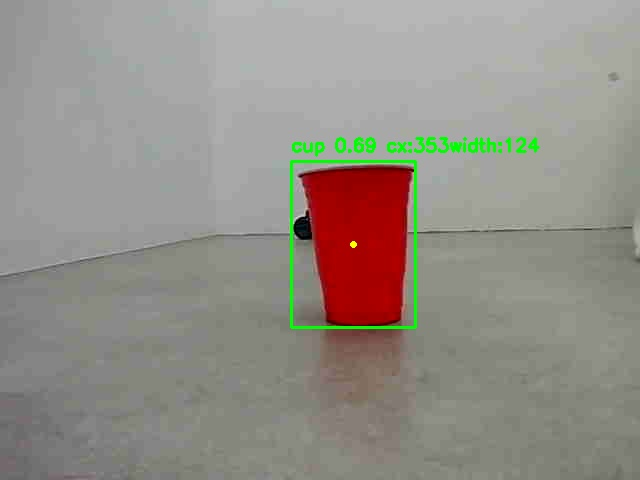

In [25]:
diagnoal_approach_stop()